# mini-vLLM, Part 4: Paged KV Cache

**What we will build and measure**

[Stage 4](https://github.com/chizkidd/minivllm/blob/main/03_continuous_batching.ipynb) ended with a diagnosis:
>_continuous batching keeps the batch full, so the next limit is memory. Each slot still reserves a worst-case rectangle, whatever its request needs, so only a minority of the pool holds tokens and the number of sequences that fit is capped by the reservation, not by the data._

**Stage 5, the paged KV cache** removes the reservation, then measures what that buys and what it costs.

1. **Cut the KV memory into blocks:** a pool of small fixed-size blocks, a block allocator, and a per-sequence block table that says which blocks hold which tokens. A request holds the blocks it needs and returns them the moment it finishes. Prove it still produces exactly the same tokens as running each request alone, even when its blocks are scattered over the pool.
2. **Measure the capacity:** at the *same KV memory*, how many more sequences run at once, and what does that do to goodput and latency?
3. **Measure where the memory goes:** how much of the pool holds tokens before and after, and what is left over (rounding to whole blocks).
4. **Measure the price:** attention now reads its keys and values through a block table. How much does that gather cost, and how does the block size trade waste against speed?
5. **Measure it under load:** requests arrive over time and both caches have the same memory. Where does each stop keeping up?

**How to use this notebook.** Same shape as the earlier parts: *Goal, Concept, Code, Result, Takeaway*, with a prediction before every benchmark. The takeaways are written as "how to read the result" because the numbers come from your run.

| # | Section | What we learn | Approx. runtime on a Kaggle T4 |
| --- | --- | --- | --- |
| 1 | Setup | Reproducible environment | seconds |
| 2 | The code | A block allocator, a paged cache, the paged scheduler | seconds |
| 3 | Load model and correctness gates | Paging reproduces one-at-a-time results | about 1 min |
| 4 | A. Same memory, more sequences | Capacity, goodput and latency at a fixed KV budget | about 4 min |
| 5 | B. Where the memory goes | Tokens stored, reserved, rounded, unused | seconds (reuses section 4 runs) |
| 6 | C. The price: gather and block size | Waste vs speed as the block size changes | about 2 min |
| 7 | D. Open-loop load at fixed memory | Latency and throughput as the offered load rises | about 5 min |
| 8 | Save results | JSON and figure inventory | seconds |
| 9 | Publish (optional) | Push results (and code, if newest) to GitHub | seconds |
| 10 | Summary | Findings and what comes next | seconds |

**Kaggle setup:** Accelerator = GPU T4 x2 (we use only the first GPU), Internet = On. Run top to bottom and restart the kernel before the final run. Set `QUICK = True` in the setup cell for a run of about 5 minutes instead of about 15.

**Self-contained.** Like the earlier parts, the `%%writefile` cells write the whole `minivllm/` and `bench/` packages and the notebook imports them. Files that did not change since Part 3 are repeated verbatim. `minivllm/block_allocator.py` is new, `minivllm/kv_cache.py` gained `PagedCache`, `minivllm/scheduler.py` gained `run_paged`, and `bench/metrics.py` gained `sweep_memory` and the memory fields of `summarize_online`.

---
## 1. Setup

**Goal:** one imports cell, one environment record.

- `CUDA_VISIBLE_DEVICES=0` is set *before* importing torch, so "we only use one GPU" is enforced rather than assumed.
- `ENV` records GPU, torch, transformers and python versions, saved with the results.
- `SEED` fixes the synthetic requests, so every cache and every memory budget sees exactly the same ones.
- `QUICK = True` shrinks the sweeps (fewer requests, memory budgets, block sizes and load levels) for a fast pass.
- After editing a `%%writefile` cell, re-run it and then restart the kernel (or reload the module), because modules that were already imported keep their old code.

In [1]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle T4 x2: use one GPU only

import gc, platform

import numpy as np
import pandas as pd
import torch, transformers

for d in ("minivllm", "bench", "results"):
    os.makedirs(d, exist_ok=True)
for pkg in ("minivllm", "bench"):
    open(f"{pkg}/__init__.py", "a").close()

assert torch.cuda.is_available(), "Turn on a GPU accelerator in Kaggle settings"

QUICK = False   # True: fewer requests, budgets, block sizes and load levels (about 5 minutes instead of about 15)
SEED = 0

ENV = {
    "gpu": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "python": platform.python_version(),
}
print(ENV)

{'gpu': 'Tesla T4', 'torch': '2.11.0+cu128', 'transformers': '5.16.1', 'python': '3.13.15'}


---
## 2. The code

Three files changed in an important way. Read them in this order: the allocator and the paged cache, the scheduler, then the benchmark helpers. The files that did not change follow at the end of this section.

### 2.1 Blocks, a block table and a cache made of them (`minivllm/block_allocator.py`, `minivllm/kv_cache.py`)

**Concept.** Stage 4's `SlotCache` gives every sequence a contiguous rectangle sized for the longest request the server may ever see. `PagedCache` cuts the same memory into small **blocks** of `block_size` tokens and keeps them in one shared pool. A sequence owns a list of block ids, its **block table**, and token `t` of the sequence lives in block `table[t // block_size]` at offset `t % block_size`.

```
pool, K and V each: [n_layers, num_blocks, n_kv_heads, block_size, head_dim]

block:    0     1     2     3     4     5     6     7
        [ A0 ][ B0 ][ A1 ][ C0 ][ B1 ][ A2 ][free][free]

block table of A: [0, 2, 5]     (A's tokens 0-15 in block 0, 16-31 in block 2, ...)
block table of B: [1, 4]
block table of C: [3]
```

The blocks of one sequence do not have to be neighbours, so a finished request returns its blocks and the next request can use them wherever they are. That is the whole idea: **memory is handed out in small units on demand, so nothing is reserved for the worst case.**

- **`BlockAllocator`** only tracks which block ids are free. It does not know about tensors or tokens. It recycles free blocks in release order, so after some churn the blocks of a sequence really are scattered.
- **`PagedCache.add(seq, tokens)`** reserves the blocks a request will need, `tokens` = its prompt plus the tokens it will store. We reserve the whole request when it is admitted, so a running sequence can never run out of blocks half way. The reservation is the request's true size, not the largest request's size. (Reserving lazily, one block at a time, is more frugal but needs preemption when the pool runs dry. That is exercise 1.)
- **`prefill_view(seq)`:** one new prompt, batch 1, no padding, written into the sequence's blocks. The prompt attends to the keys it just computed, so nothing is gathered.
- **`decode_view(seqs)`:** one token for each *running* sequence, written at its own position (block `table[len // block_size]`, offset `len % block_size`). The keys and values of those sequences are then **gathered through their block tables** into one dense tensor, and ordinary attention runs on it, with the same per-sequence mask as in Stage 4. There are no dummy rows for free slots, because the batch is exactly the running sequences.

The gather is an honest cost. A real paged-attention kernel (vLLM's) reads the blocks in place. Here we copy them into a dense tensor first and reuse the attention we already have, which keeps the code short and the maths identical. Section 6 measures what the copy costs.

### 2.2 Continuous batching on a paged cache (`minivllm/scheduler.py`)

**Concept.** `run_paged` is `run_continuous` with two differences:

- **Admission is by memory.** There are no slots. The request at the head of the queue is admitted when the pool has enough free blocks for all it will store, and when fewer than `max_seqs` sequences run. If it does not fit it waits, and nobody behind it jumps ahead, so the order stays first come, first served. Its blocks go back to the pool the moment it finishes.
- **The decode batch is the running sequences**, gathered through their block tables.

Everything else is unchanged: the virtual clock, one prefill per new request, release at once, and the `max_prefills` budget. Each decode step also records how many tokens are stored, reserved and handed out, and whether the head of the queue was held back by memory.

In [2]:
%%writefile minivllm/model.py
import torch
import torch.nn.functional as F

def rms_norm(x, weight, eps):
    xf = x.float()
    xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + eps)
    return weight * xf.to(x.dtype)

def rotate_half(x):
    h = x.shape[-1] // 2
    return torch.cat((-x[..., h:], x[..., :h]), dim=-1)

def apply_rope(x, cos, sin):
    return x * cos + rotate_half(x) * sin

class MiniQwen:
    def __init__(self, hf_model, max_pos=2048):
        cfg = hf_model.config
        self.n_layers = cfg.num_hidden_layers
        self.n_heads = cfg.num_attention_heads
        self.n_kv = cfg.num_key_value_heads
        self.hd = getattr(cfg, "head_dim", None) or cfg.hidden_size // self.n_heads
        self.n_rep = self.n_heads // self.n_kv
        self.eps = cfg.rms_norm_eps

        m = hf_model.model
        self.embed = m.embed_tokens.weight
        self.norm_w = m.norm.weight
        self.lm_head = hf_model.lm_head.weight
        self.device, self.dtype = self.embed.device, self.embed.dtype
        self.layers = []
        for l in m.layers:
            a, mlp = l.self_attn, l.mlp
            self.layers.append(dict(
                ln1=l.input_layernorm.weight, ln2=l.post_attention_layernorm.weight,
                q_w=a.q_proj.weight, q_b=a.q_proj.bias,
                k_w=a.k_proj.weight, k_b=a.k_proj.bias,
                v_w=a.v_proj.weight, v_b=a.v_proj.bias,
                o_w=a.o_proj.weight,
                gate=mlp.gate_proj.weight, up=mlp.up_proj.weight, down=mlp.down_proj.weight,
            ))

        theta = getattr(cfg, "rope_theta", None)
        if theta is None:
            theta = cfg.rope_parameters["rope_theta"]
        inv = 1.0 / (theta ** (torch.arange(0, self.hd, 2, device=self.device).float() / self.hd))
        t = torch.arange(max_pos, device=self.device).float()
        emb = torch.cat([torch.outer(t, inv)] * 2, dim=-1)
        self.cos, self.sin = emb.cos().to(self.dtype), emb.sin().to(self.dtype)

    @torch.no_grad()
    def forward(self, ids, cache=None, positions=None, attn_mask=None):
        """
        ids: [B, T]. Returns logits for the LAST position only: [B, vocab].
        Batching of sequences with different lengths (Stage 3) adds two optional inputs:
          positions: [B, T] RoPE position of every token (default: consecutive from the cache length).
          attn_mask: bool [B, 1, T, L], True = this query may attend to this key, where L is the
                     number of keys after the cache update (default: causal, no padding).
        """
        B, T = ids.shape
        pos0 = cache.length if cache is not None else 0
        assert not (cache is not None and T > 1 and pos0 > 0), "prefill only from an empty cache"
        if positions is None:
            assert pos0 + T <= self.cos.shape[0], "sequence longer than RoPE table"
            cos = self.cos[pos0:pos0 + T][None, None]
            sin = self.sin[pos0:pos0 + T][None, None]
        else:
            cos = self.cos[positions][:, None]   # [B, 1, T, head_dim]
            sin = self.sin[positions][:, None]

        x = F.embedding(ids, self.embed)
        for i, L in enumerate(self.layers):
            h = rms_norm(x, L["ln1"], self.eps)
            q = F.linear(h, L["q_w"], L["q_b"]).view(B, T, self.n_heads, self.hd).transpose(1, 2)
            k = F.linear(h, L["k_w"], L["k_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            v = F.linear(h, L["v_w"], L["v_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
            if cache is not None:
                k, v = cache.update(i, k, v)
            # Expand KV heads to match query heads (GQA). Wasteful, a known optimization target.
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)
            a = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                               is_causal=(attn_mask is None and T > 1))
            a = a.transpose(1, 2).reshape(B, T, -1)
            x = x + F.linear(a, L["o_w"])
            h = rms_norm(x, L["ln2"], self.eps)
            x = x + F.linear(F.silu(F.linear(h, L["gate"])) * F.linear(h, L["up"]), L["down"])
        if cache is not None:
            cache.advance(T)
        x = rms_norm(x[:, -1], self.norm_w, self.eps)
        return F.linear(x, self.lm_head)

Writing minivllm/model.py


### 2.3 Unchanged from Part 3

`minivllm/model.py` (forward with optional `positions` and `attn_mask`), `minivllm/batching.py` (`left_pad`, `Layout`), `minivllm/engine.py` (`generate_cached`, our one-at-a-time reference) and `minivllm/utils.py`. `SlotCache` and `run_continuous` are still in `kv_cache.py` and `scheduler.py`, because the contiguous cache is the baseline.

In [3]:
%%writefile minivllm/batching.py
import torch

def left_pad(seqs, pad_id, device, pad_to=None):
    """
    Stack variable-length token lists into one [B, T] tensor, padding on the LEFT so that the
    last column is a real token for every sequence (generation reads the last position).
    Returns (ids [B, T], lens [B]) where lens are the real prompt lengths. `pad_to` forces a
    longer T than the longest prompt (e.g. to round up to a multiple of 8). 
    
    If you use `pad_to`, build the matching `Layout(..., T=ids.shape[1])` too: Layout assumes 
    the longest prompt otherwise, and its positions and masks would not fit the tensor.
    """
    lens = [len(s) for s in seqs]
    T = max(lens + [pad_to or 0])
    ids = torch.full((len(seqs), T), pad_id, dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, T - len(s):] = torch.as_tensor(s, dtype=torch.long)
    return ids.to(device), torch.tensor(lens, device=device)

class Layout:
    """
    Positions and attention masks for one wave of left-padded sequences.
    
      column:   0 1 2 3 4 5 | 6 7 8 ...      T = longest prompt, then generated tokens follow
      seq A:    . . A A A A | g g g          (. = padding, A = prompt token, g = generated)
      seq B:    . B B B B B | g g g
    
    Every sequence shares the same cache columns, so the cache stays a single rectangle. Padding
    columns are never attended to, and RoPE positions count only real tokens (A starts at 0).
    """                                                                         
    def __init__(self, lens, max_new, device, T=None):
        self.lens = lens.to(device)                         # [B] real prompt lengths
        self.T = T or int(self.lens.max())                  # padded prompt length (columns)
        self.device = device
        self.pad = self.T - self.lens                       # [B] padding columns per sequence
        cols = torch.arange(self.T + max_new, device=device)
        self.key_real = cols[None, :] >= self.pad[:, None]  # [B, T + max_new]: True on real tokens

    def prefill(self):
        """positions [B, T] and mask [B, 1, T, T] for the prompt pass."""
        T, dev = self.T, self.device
        cols = torch.arange(T, device=dev)
        positions = (cols[None, :] - self.pad[:, None]).clamp(min=0)
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=dev))
        mask = causal[None] & self.key_real[:, None, :T]
        # A padding query would otherwise have no key to attend to. A fully masked row makes the
        # softmax NaN, and 0 * NaN is NaN, so it would poison real tokens. Let it see itself.
        mask = mask | torch.eye(T, dtype=torch.bool, device=dev)[None]
        return positions, mask[:, None]

    def decode(self, j):
        """
        positions [B, 1] and mask [B, 1, 1, L] for the step that consumes generated token j
        (j = 1 is the token the prompt pass produced). It sits in cache column T + j - 1.
        """
        positions = (self.lens + (j - 1))[:, None]
        mask = self.key_real[:, None, None, :self.T + j]
        return positions, mask

Writing minivllm/batching.py


In [4]:
%%writefile minivllm/block_allocator.py
from collections import deque


class BlockAllocator:
    """
    A pool of `num_blocks` fixed-size KV blocks, handed out and taken back by id.

    The allocator knows nothing about tensors or tokens: it only tracks which block ids are free. A sequence
    that needs `n` blocks gets a list of `n` ids (its block table) and gives them back when it finishes, so
    memory freed by one request is immediately usable by the next, whatever their lengths.

    Free ids are kept in a FIFO queue. That is not required for correctness, but it recycles blocks in
    release order, so after some churn a sequence's blocks are scattered over the pool instead of forming one
    contiguous run, which is exactly the situation a block table exists to handle.
    """
    def __init__(self, num_blocks):
        assert num_blocks > 0
        self.num_blocks = num_blocks
        self._free = deque(range(num_blocks))
        self._in_use = [False] * num_blocks

    @property
    def num_free(self):
        return len(self._free)

    @property
    def num_used(self):
        return self.num_blocks - len(self._free)

    def can_allocate(self, n):
        return n <= len(self._free)

    def allocate(self, n):
        """Take `n` free blocks. Returns their ids; raises if the pool cannot supply them."""
        if not self.can_allocate(n):
            raise MemoryError(f"need {n} blocks, only {len(self._free)} free")
        ids = [self._free.popleft() for _ in range(n)]
        for b in ids:
            self._in_use[b] = True
        return ids

    def free(self, ids):
        """Give blocks back. Freeing a block that is not in use is a bug (a double free), so it raises."""
        for b in ids:
            if not self._in_use[b]:
                raise ValueError(f"block {b} is not in use")
            self._in_use[b] = False
            self._free.append(b)

Writing minivllm/block_allocator.py


In [5]:
%%writefile minivllm/kv_cache.py
import torch
import torch.nn.functional as F

from .block_allocator import BlockAllocator

class KVCache:
    """
    Contiguous, preallocated cache for a batch of sequences.
    Each tensor has shape [n_layers, batch, n_kv_heads, max_len, head_dim].
    """
    def __init__(self, n_layers, batch, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, batch, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.length = 0
        self.max_len = max_len

    def update(self, layer, k, v):
        """k, v: [batch, n_kv_heads, T, head_dim]. Returns everything cached so far."""
        T = k.shape[2]
        end = self.length + T
        assert end <= self.max_len, "KV cache overflow"
        self.k[layer, :, :, self.length:end] = k
        self.v[layer, :, :, self.length:end] = v
        return self.k[layer, :, :, :end], self.v[layer, :, :, :end]

    def advance(self, T):
        """Called once per forward pass, after all layers have written."""
        self.length += T

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()

    @staticmethod
    def bytes_per_token(n_layers, n_kv_heads, head_dim, dtype_bytes=2):
        return 2 * n_layers * n_kv_heads * head_dim * dtype_bytes


class SlotCache:
    """
    A fixed pool of `slots` sequence slots, each with room for `max_len` tokens, for continuous batching.
    Shape [n_layers, slots, n_kv_heads, max_len, head_dim], like KVCache, but every slot has its OWN length
    (`lens`). A finished sequence frees its slot at once and a waiting request is prefilled into it, while
    the other slots keep decoding. Each slot is still one contiguous worst-case rectangle (Stage 5 replaces
    that with blocks).

    model.forward only needs `length`, `update` and `advance`, so two small views plug the pool into it:
      prefill_view(slot): one new prompt (batch 1, no padding) written into one free slot.
      decode_view():      one token for EVERY slot at its own column. Slots that are free decode a dummy
                          token that is masked and overwritten later, which keeps the batch shape fixed.
    """
    def __init__(self, n_layers, slots, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, slots, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.slots, self.max_len, self.device = slots, max_len, device
        self.lens = [0] * slots     # tokens stored per slot; plain ints, so reading them never syncs the GPU

    def prefill_view(self, slot):
        return _PrefillView(self, slot)

    def decode_view(self):
        return _DecodeView(self)

    def free(self, slot):
        self.lens[slot] = 0

    @property
    def used_tokens(self):
        return sum(self.lens)

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty slot

    def __init__(self, cache, slot):
        assert cache.lens[slot] == 0, "slot is not free"
        self.c, self.slot = cache, slot

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]."""
        T = k.shape[2]
        assert T <= self.c.max_len, "KV slot overflow"
        self.c.k[layer, self.slot, :, :T] = k[0]
        self.c.v[layer, self.slot, :, :T] = v[0]
        return self.c.k[layer, self.slot:self.slot + 1, :, :T], self.c.v[layer, self.slot:self.slot + 1, :, :T]

    def advance(self, T):
        self.c.lens[self.slot] = T


class _DecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache):
        self.c = cache
        self.rows = torch.arange(cache.slots, device=cache.device)
        self.cols = torch.tensor(cache.lens, device=cache.device)   # the column each slot writes its new token to
        self.end = max(cache.lens) + 1                               # columns that can matter this step
        assert self.end <= cache.max_len, "KV slot overflow"

    def update(self, layer, k, v):
        """k, v: [slots, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every slot."""
        self.c.k[layer, self.rows, :, self.cols] = k[:, :, 0]
        self.c.v[layer, self.rows, :, self.cols] = v[:, :, 0]
        return self.c.k[layer, :, :, :self.end], self.c.v[layer, :, :, :self.end]

    def advance(self, T):
        pass     # the scheduler advances only the slots that are actually running


class PagedCache:
    """
    A KV cache made of fixed-size blocks drawn from one shared pool (Stage 5).
    Each tensor has shape [n_layers, num_blocks, n_kv_heads, block_size, head_dim]. A sequence does not own a
    rectangle: it owns a list of block ids (its block table) and a length, and token t of the sequence lives in
    block table[t // block_size] at offset t % block_size. Blocks are handed out by a BlockAllocator when a
    sequence is added and returned the moment it is freed, so a request holds memory for the tokens it needs,
    not for the longest request the server might ever see.

    Sequences are named by any hashable id (we use the request id). `add(seq, tokens)` reserves enough blocks
    for the whole request, `tokens` = prompt + generated tokens that will be stored, so a running sequence can
    never run out of blocks half way (Stage 5 keeps admission simple; reserving lazily needs preemption,
    which is exercise 1).

    model.forward only needs `length`, `update` and `advance`, so two views plug the pool into it, as for SlotCache:
      prefill_view(seq):  one new prompt (batch 1, no padding) written into the sequence's blocks.
      decode_view(seqs):  one token for each listed sequence, each written at its own position. The keys and
                          values of those sequences are gathered through their block tables into one dense
                          tensor, then ordinary attention runs on it.
    """
    def __init__(self, n_layers, num_blocks, block_size, n_kv_heads, head_dim, device, dtype):
        shape = (n_layers, num_blocks, n_kv_heads, block_size, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.num_blocks, self.block_size, self.device = num_blocks, block_size, device
        self.n_kv_heads, self.head_dim = n_kv_heads, head_dim
        self.allocator = BlockAllocator(num_blocks)
        self.tables = {}     # seq -> list of block ids
        self.lens = {}       # seq -> tokens stored (plain ints, so reading them never syncs the GPU)
        self.cap = {}        # seq -> tokens reserved for it

    def blocks_for(self, tokens):
        return -(-tokens // self.block_size)

    def can_admit(self, tokens):
        return self.allocator.can_allocate(self.blocks_for(tokens))

    def add(self, seq, tokens):
        """Reserve blocks for a sequence that will store up to `tokens` tokens."""
        assert seq not in self.tables, "sequence already in the cache"
        self.tables[seq] = self.allocator.allocate(self.blocks_for(tokens))
        self.lens[seq], self.cap[seq] = 0, tokens

    def free(self, seq):
        """Give the sequence's blocks back to the pool. Their contents are not erased, only forgotten."""
        self.allocator.free(self.tables.pop(seq))
        del self.lens[seq], self.cap[seq]

    def prefill_view(self, seq):
        return _PagedPrefillView(self, seq)

    def decode_view(self, seqs):
        return _PagedDecodeView(self, list(seqs))

    @property
    def used_tokens(self):
        """Tokens actually stored."""
        return sum(self.lens.values())

    @property
    def reserved_tokens(self):
        """Tokens the running sequences will have stored when they finish."""
        return sum(self.cap.values())

    @property
    def allocated_tokens(self):
        """Token capacity of the blocks handed out (reserved tokens rounded up to whole blocks)."""
        return self.allocator.num_used * self.block_size

    @property
    def bytes_per_block(self):
        return 2 * self.k.shape[0] * self.k[0, 0].numel() * self.k.element_size()

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PagedPrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty sequence

    def __init__(self, cache, seq):
        assert cache.lens[seq] == 0, "sequence already has tokens"
        self.c, self.seq = cache, seq

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]. Writes them block by block and returns them unchanged."""
        c, T = self.c, k.shape[2]
        assert T <= c.cap[self.seq], "KV reservation overflow"
        nb = c.blocks_for(T)
        blocks = torch.tensor(c.tables[self.seq][:nb], device=c.device)
        pad = nb * c.block_size - T
        for cache_t, x in ((c.k, k), (c.v, v)):
            # [n_kv, T, hd] -> pad the last block with zeros -> [nb, n_kv, block_size, hd]
            x = F.pad(x[0], (0, 0, 0, pad)).view(c.n_kv_heads, nb, c.block_size, c.head_dim).transpose(0, 1)
            cache_t[layer, blocks] = x
        return k, v   # a prefill attends to the prompt it just computed, so there is nothing to gather

    def advance(self, T):
        self.c.lens[self.seq] = T


class _PagedDecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache, seqs):
        self.c = cache
        bs = cache.block_size
        lens = [cache.lens[s] for s in seqs]
        assert all(l < cache.cap[s] for s, l in zip(seqs, lens)), "KV reservation overflow"
        self.end = max(lens) + 1                      # columns that can matter this step
        nb = cache.blocks_for(self.end)
        # Block table of the batch, [n, nb]. A sequence with fewer blocks is padded with block 0: those columns
        # lie beyond its position, so the attention mask hides whatever they hold.
        table = [(cache.tables[s] + [0] * nb)[:nb] for s in seqs]
        self.table = torch.tensor(table, device=cache.device)
        self.wblk = torch.tensor([cache.tables[s][l // bs] for s, l in zip(seqs, lens)], device=cache.device)
        self.woff = torch.tensor([l % bs for l in lens], device=cache.device)

    def update(self, layer, k, v):
        """k, v: [n, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every sequence, gathered."""
        c = self.c
        c.k[layer, self.wblk, :, self.woff] = k[:, :, 0]
        c.v[layer, self.wblk, :, self.woff] = v[:, :, 0]
        n, nb = self.table.shape
        out = []
        for cache_t in (c.k, c.v):
            g = cache_t[layer][self.table]                                    # [n, nb, n_kv, block_size, hd]
            g = g.permute(0, 2, 1, 3, 4).reshape(n, c.n_kv_heads, nb * c.block_size, c.head_dim)
            out.append(g[:, :, :self.end])
        return out[0], out[1]

    def advance(self, T):
        pass     # the scheduler advances only the sequences that are actually running

Writing minivllm/kv_cache.py


In [6]:
%%writefile minivllm/scheduler.py
import time
from collections import deque
from dataclasses import dataclass, field
import torch
from .kv_cache import KVCache, SlotCache, PagedCache
from .batching import left_pad, Layout

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@dataclass
class Request:
    id: int
    prompt_ids: list      # token ids of the prompt
    max_new: int          # tokens to generate (stands in for "until EOS" with synthetic prompts)
    arrival_s: float = 0.0   # when the request arrives, seconds from run start (Stage 4 load; Stage 3 uses 0 for all)

@dataclass
class RequestResult:
    id: int
    wave: int
    prompt_len: int
    max_new: int
    tokens: list          # the max_new generated token ids
    first_token_s: float  # seconds from run start to the first token
    finish_s: float       # seconds from run start to this request's own last token
    release_s: float      # seconds from run start until its wave ends and the batch returns

@dataclass
class StaticRun:
    results: list
    waves: list           # one dict per wave (see run_static)
    total_s: float

@torch.no_grad()
def run_static(model, requests, batch_size, pad_id=0):
    """
    Static batching: take the next `batch_size` requests, left-pad them into one batch, prefill
    once, then decode until the LONGEST request in the batch is done. A request that finishes
    early keeps its slot and keeps being computed (wasted work) until the whole batch ends.
    All requests arrive at t = 0 and waves run back to back.
    """
    results, waves = [], []
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd,
                                  torch.empty((), dtype=model.dtype).element_size())
    t_run = _tick()
    for w, start in enumerate(range(0, len(requests), batch_size)):
        wave = requests[start:start + batch_size]
        B = len(wave)
        max_new = max(r.max_new for r in wave)
        ids, lens = left_pad([r.prompt_ids for r in wave], pad_id, model.device)
        T = ids.shape[1]
        assert T + max_new <= model.cos.shape[0], "wave longer than the RoPE table"
        layout = Layout(lens, max_new, model.device)
        # The last generated token is never fed back in, so it is never stored: T + max_new - 1 columns.
        cache = KVCache(model.n_layers, B, model.n_kv, T + max_new - 1, model.hd, model.device, model.dtype)

        t0 = _tick()
        positions, mask = layout.prefill()
        nxt = model.forward(ids, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
        prev = _tick()
        ttft = prev - t0
        out, step_times = [nxt], []
        for j in range(1, max_new):
            positions, mask = layout.decode(j)
            nxt = model.forward(nxt, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
            now = _tick()
            step_times.append(now - prev)
            prev = now
            out.append(nxt)
        toks = torch.cat(out, dim=1).cpu()
        t_end = _tick()

        # When did each request produce its own last token?
        cum = [ttft]
        for s in step_times:
            cum.append(cum[-1] + s)
        for i, r in enumerate(wave):
            results.append(RequestResult(
                id=r.id, wave=w, prompt_len=len(r.prompt_ids), max_new=r.max_new,
                tokens=toks[i, :r.max_new].tolist(),
                first_token_s=(t0 - t_run) + ttft,
                finish_s=(t0 - t_run) + cum[r.max_new - 1],
                release_s=t_end - t_run))
        lens_l = [len(r.prompt_ids) for r in wave]
        waves.append(dict(
            wave=w, B=B, T=T, max_new=max_new,
            prompt_real=sum(lens_l), prompt_slots=B * T,
            decode_slot_steps=B * (max_new - 1),
            decode_useful=sum(r.max_new - 1 for r in wave),
            useful_tokens=sum(r.max_new for r in wave),
            ttft_s=ttft, step_times=step_times, wave_s=t_end - t0,
            kv_alloc_bytes=cache.nbytes,
            kv_used_bytes=bpt * sum(l + r.max_new - 1 for l, r in zip(lens_l, wave))))   # real tokens actually stored
    return StaticRun(results=results, waves=waves, total_s=_tick() - t_run)


# ---------------------------------------------------------------------------------------------
# Stage 4: requests arrive over time, and the server either batches them statically or continuously.
# Both policies run on a virtual clock: it advances by the measured GPU time of each step and jumps
# over idle gaps, so a low-load run takes seconds, not minutes, and latency is still exact.

@dataclass
class OnlineResult:
    id: int
    prompt_len: int
    max_new: int
    arrival_s: float       # when the request arrived
    admit_s: float         # when its prefill (or its batch) started: arrival to admit is queueing
    first_token_s: float   # when its first token existed
    finish_s: float        # when its own last token existed
    release_s: float       # when the caller got the answer (static: its batch ended; continuous: finish_s)
    tokens: list

@dataclass
class OnlineRun:
    results: list          # one OnlineResult per request, ordered by request id
    steps: list            # continuous: one dict per decode step (start_s, step_s, active, kv_tokens, gap_s); paged adds
                           # kv_alloc_tokens, kv_need_tokens, waiting, mem_blocked; static: empty
    prefills: list         # continuous: one dict per prefill (id, start_s, prefill_s, prompt_len); static: empty
    makespan_s: float      # virtual time when the last request was released
    busy_s: float          # time the GPU was working (makespan minus idle gaps)
    policy: str
    slots: int             # concurrency limit: batch size (static), slot count (continuous) or max sequences (paged)
    max_len: int = 0       # tokens each slot can hold (continuous)
    pool_tokens: int = 0   # token capacity of the whole KV pool (paged: blocks * block_size)
    block_size: int = 0    # tokens per block (paged)

@torch.no_grad()
def run_static_online(model, requests, batch_size, pad_id=0):
    """
    Static batching under arrivals. Whenever the GPU is free it takes the requests that have already
    arrived, up to `batch_size` (it does not wait for a full batch), and runs them as one static wave
    exactly as run_static does. If nothing is waiting it idles until the next arrival.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    results, now, busy = [], 0.0, 0.0
    while pending:
        now = max(now, pending[0].arrival_s)                       # idle until someone arrives
        wave = []
        while pending and pending[0].arrival_s <= now and len(wave) < batch_size:
            wave.append(pending.popleft())
        sub = run_static(model, wave, batch_size=len(wave), pad_id=pad_id)
        for r, res in zip(wave, sub.results):
            results.append(OnlineResult(
                id=r.id, prompt_len=res.prompt_len, max_new=r.max_new, arrival_s=r.arrival_s, admit_s=now,
                first_token_s=now + res.first_token_s, finish_s=now + res.finish_s,
                release_s=now + res.release_s, tokens=res.tokens))
        now += sub.total_s
        busy += sub.total_s
    results.sort(key=lambda x: x.id)
    return OnlineRun(results=results, steps=[], prefills=[], makespan_s=now, busy_s=busy,
                     policy="static", slots=batch_size)

@torch.no_grad()
def run_continuous(model, requests, slots, pad_id=0, max_prefills=None):
    """
    Continuous (iteration-level) batching with a pool of `slots` sequence slots. Every iteration:
      1. requests that have arrived join a FIFO queue,
      2. free slots are filled from the queue: each new request is prefilled alone into its slot (no
         padding), up to `max_prefills` per iteration (None = fill every free slot),
      3. one decode step runs for all slots, each at its own position,
      4. a request that reached its max_new is released at once and its slot is free for step 2.
    So nothing waits for a stranger's long answer, and no slot idles while someone is queued.
    Free slots decode a dummy token that is masked out, which keeps the batch shape fixed.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in pending)
    assert max_len + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = SlotCache(model.n_layers, slots, model.n_kv, max_len, model.hd, model.device, model.dtype)
    waiting, running = deque(), {}                 # running: slot -> state of the request in it
    last = [pad_id] * slots                        # the token each slot feeds into its next decode step
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0     # end time of the last decode step, and how many requests it left running

    def finish(slot, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(slot)
        last[slot] = pad_id
        running.pop(slot, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        for slot in range(slots):
            if not waiting or (max_prefills is not None and admitted >= max_prefills):
                break
            if slot in running:
                continue
            r = waiting.popleft()
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(slot)).argmax(-1))     # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(slot, st, now)
            else:
                running[slot] = st
                last[slot] = tok

        if running:
            t0 = _tick()
            lens = list(cache.lens)
            view = cache.decode_view()
            positions = torch.tensor(lens, device=model.device)[:, None]                        # [slots, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            nxt = model.forward(torch.tensor(last, device=model.device)[:, None], view,
                                positions=positions, attn_mask=mask).argmax(-1).tolist()      # .tolist() waits
            dt = _tick() - t0
            # gap_s: what a request that was already running sees between two tokens, i.e. this step plus any
            # prefills that ran in between (None if nothing was running after the previous step)
            steps.append(dict(start_s=now, step_s=dt, active=len(running), kv_tokens=sum(lens) + len(running),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for slot, st in list(running.items()):
                cache.lens[slot] += 1
                st["tokens"].append(nxt[slot])
                last[slot] = nxt[slot]
                if len(st["tokens"]) == st["req"].max_new:
                    finish(slot, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="continuous", slots=slots, max_len=max_len)


@torch.no_grad()
def run_paged(model, requests, num_blocks, block_size=16, max_seqs=32, pad_id=0, max_prefills=None):
    """
    Continuous batching on a paged KV cache (Stage 5). It is run_continuous with two differences:
      memory:  there are no slots. A request is admitted when a free block can hold everything it will store
               (prompt + max_new - 1 tokens), and its blocks go back to the pool when it finishes. The head of
               the queue waits for memory and nobody jumps ahead of it (first come, first served).
      batch:   a decode step runs only the sequences that are running, gathering their keys and values through
               their block tables, so there are no dummy rows. `max_seqs` caps how many run at once.
    Everything else (virtual clock, prefill per request, release at once) is as in run_continuous.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    need = {r.id: len(r.prompt_ids) + r.max_new - 1 for r in pending}
    assert max(need.values()) + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = PagedCache(model.n_layers, num_blocks, block_size, model.n_kv, model.hd, model.device, model.dtype)
    assert cache.blocks_for(max(need.values())) <= num_blocks, "the pool cannot hold the largest request"
    waiting, running = deque(), {}                 # running: request id -> state (insertion order = admission order)
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0

    def finish(seq, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(seq)
        running.pop(seq, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        while (waiting and len(running) < max_seqs and (max_prefills is None or admitted < max_prefills)
               and cache.can_admit(need[waiting[0].id])):
            r = waiting.popleft()
            cache.add(r.id, need[r.id])
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(r.id)).argmax(-1))      # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(r.id, st, now)
            else:
                running[r.id] = st

        if running:
            t0 = _tick()
            seqs = list(running)
            lens = [cache.lens[s] for s in seqs]
            view = cache.decode_view(seqs)
            positions = torch.tensor(lens, device=model.device)[:, None]                         # [n, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            last = torch.tensor([running[s]["tokens"][-1] for s in seqs], device=model.device)[:, None]
            nxt = model.forward(last, view, positions=positions, attn_mask=mask).argmax(-1).tolist()   # waits
            dt = _tick() - t0
            steps.append(dict(start_s=now, step_s=dt, active=len(seqs), kv_tokens=sum(lens) + len(seqs),
                              kv_alloc_tokens=cache.allocated_tokens, kv_need_tokens=cache.reserved_tokens,
                              waiting=len(waiting),
                              mem_blocked=bool(waiting) and len(running) < max_seqs and not cache.can_admit(need[waiting[0].id]),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for seq, tok in zip(seqs, nxt):
                st = running[seq]
                cache.lens[seq] += 1
                st["tokens"].append(tok)
                if len(st["tokens"]) == st["req"].max_new:
                    finish(seq, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="paged", slots=max_seqs,
                     pool_tokens=num_blocks * block_size, block_size=block_size)

Writing minivllm/scheduler.py


In [7]:
%%writefile minivllm/engine.py
import time
import torch
from .kv_cache import KVCache

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@torch.no_grad()
def generate_naive(model, ids, n_new):
    """No cache: recompute the full sequence for every new token."""
    for _ in range(n_new):
        nxt = model.forward(ids).argmax(-1, keepdim=True)
        ids = torch.cat([ids, nxt], dim=1)
    return ids

@torch.no_grad()
def generate_cached(model, ids, n_new, decode_fn=None):
    """
    Prefill once, then decode one token at a time using the cache.
    decode_fn(ids, cache) -> logits replaces model.forward for the decode steps only
    (e.g. a torch.compile'd forward). Prefill always runs eagerly.
    Returns (all_ids, {"ttft": seconds, "itl": [seconds per decode step]}).
    """
    decode = decode_fn or model.forward
    B, T = ids.shape
    cache = KVCache(model.n_layers, B, model.n_kv, T + n_new, model.hd, ids.device, model.dtype)
    t0 = _tick()
    nxt = model.forward(ids, cache).argmax(-1, keepdim=True)
    prev = _tick()
    ttft = prev - t0
    out, itl = [nxt], []
    for _ in range(n_new - 1):
        nxt = decode(nxt, cache).argmax(-1, keepdim=True)
        now = _tick()
        itl.append(now - prev)
        prev = now
        out.append(nxt)
    return torch.cat([ids] + out, dim=1), {"ttft": ttft, "itl": itl}

Writing minivllm/engine.py


In [8]:
%%writefile minivllm/utils.py
def first_mismatch(a, b):
    """Index of the first position where two token lists differ, or None if they match."""
    for i, (x, y) in enumerate(zip(a, b)):
        if x != y:
            return i
    return None

Writing minivllm/utils.py


### 2.4 Benchmark helpers (`bench/`)

| Module | New in this part |
| --- | --- |
| `bench/metrics.py` | `sweep_memory` (the same requests on a contiguous and a paged cache of the *same memory*, closed batch or Poisson arrivals) and the memory fields of `summarize_online` (`kv_fill`, tokens stored, reserved and handed out, how often memory held a request back) |
| `bench/publish.py` | `publish`: copy results (and code, if newest) into a clone of the repo, commit and push |

The other helpers are unchanged. A memory budget is always given in **worst-case slots**: `b` slots of the largest request the workload can produce, which is the memory a contiguous cache needs for `b` sequences. The paged cache gets the same number of bytes, cut into blocks.

**Metrics to keep apart.**
* <u>*Tokens stored*</u> are the keys and values that actually exist.
* <u>*Tokens reserved*</u> are what the running requests will hold when they finish.
* <u>*Tokens handed out*</u> are the memory given to requests: for contiguous slots the whole pool, for paged whole blocks, so reserved tokens rounded up to a block.
* <u>*Fill*</u> is stored over handed out, the share of the memory in use that holds tokens.

In [9]:
%%writefile bench/workload.py
import random
from dataclasses import replace

from minivllm.scheduler import Request

# Named workloads. Prompt lengths are drawn from `prompt_lens`; each request is "long" with
# probability p_long (output length drawn from long_out) and "short" otherwise (from short_out).
WORKLOADS = {
    "equal": dict(prompt_lens=(128,), short_out=(64, 64), long_out=(64, 64), p_long=0.0),
    "mixed": dict(prompt_lens=(32, 64, 128, 256, 512), short_out=(16, 48), long_out=(128, 256), p_long=0.25),
}

def spread_prompt_lens(base, factor, k=5):
    """
    k prompt lengths spread geometrically from base to base * factor (factor 1 = all equal).
    Lengths are rounded to integers, so with a small base or factor several can collide and the
    result has fewer than k distinct lengths (spread_prompt_lens(10, 1.2) gives 3 values).
    """
    assert k >= 2, "need at least two lengths to spread between base and base * factor"
    return tuple(sorted({round(base * factor ** (i / (k - 1))) for i in range(k)}))

def make_requests(n, seed=0, vocab=(1000, 20000), **spec):
    """
    `spec` is a WORKLOADS entry (or the same keys); returns n Requests with random token ids.
    Fixed seeds make every run (and every batch size) see the same requests.
    Careful with the bounds: `vocab` is a half-open range (the upper id is excluded), while the
    `short_out` and `long_out` ranges for max_new are inclusive on both ends.
    """
    rng = random.Random(seed)
    reqs = []
    for i in range(n):
        plen = rng.choice(spec["prompt_lens"])
        out = spec["long_out"] if rng.random() < spec["p_long"] else spec["short_out"]
        reqs.append(Request(i, [rng.randrange(*vocab) for _ in range(plen)], rng.randint(*out)))
    return reqs

def padding_pct(spread, seed, batch=8, base=64, n_new=64):
    """
    Padding share (in %) of the prompt slots of ONE static batch of `batch` requests drawn with this seed:
    100 * (1 - real prompt tokens / (batch * longest prompt)). CPU only: it needs prompt lengths, not a model.
    It builds the requests exactly like the benchmark does, so seed=SEED reproduces the measured batch.
    """
    reqs = make_requests(batch, seed=seed, prompt_lens=spread_prompt_lens(base, spread),
                         short_out=(n_new, n_new), long_out=(n_new, n_new), p_long=0.0)
    lens = [len(r.prompt_ids) for r in reqs]
    return 100 * (1 - sum(lens) / (len(lens) * max(lens)))


def poisson_arrivals(n, rate, seed=0):
    """
    n arrival times (seconds from run start) of a Poisson process with `rate` requests per second.
    The gaps are exponential, so arrivals are bursty the way real traffic is. Fixed seed, same trace every time.
    """
    rng = random.Random(seed)
    t, times = 0.0, []
    for _ in range(n):
        t += rng.expovariate(rate)
        times.append(t)
    return times


def with_arrivals(requests, rate, seed=0):
    """
    The same requests with Poisson arrival times, in request order. Use the same trace for every policy
    you compare, so the only difference between runs is the scheduler.
    """
    times = poisson_arrivals(len(requests), rate, seed)
    return [replace(r, arrival_s=t) for r, t in zip(requests, times)]

Writing bench/workload.py


In [10]:
%%writefile bench/metrics.py
import time, statistics
import torch

def sync_time(fn, warmup=1, iters=3):
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(iters):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        fn()
        torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return statistics.median(times)

def pct(xs, q):
    xs = sorted(xs)
    return xs[min(len(xs) - 1, int(q / 100 * len(xs)))]

def bench_cached(generate_cached, model, ids, n_new, runs=3):
    """
    generate_cached: the engine's generate_cached function (passed in, not imported,
    to avoid a circular import between bench/ and minivllm/).
    """
    generate_cached(model, ids, n_new)  # warm-up
    ttfts, itls, totals = [], [], []
    for _ in range(runs):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        _, m = generate_cached(model, ids, n_new)
        torch.cuda.synchronize()
        totals.append(time.perf_counter() - t0)
        ttfts.append(m["ttft"])
        itls.extend(m["itl"])
    return {
        "n_new": n_new,
        "cached_s": statistics.median(totals),
        "cached_tok_s": n_new / statistics.median(totals),
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * pct(itls, 50),
        "itl_p99_ms": 1000 * pct(itls, 99),
    }


def bench_naive(generate_naive, model, ids, n_new, iters=3):
    t = sync_time(lambda: generate_naive(model, ids, n_new), warmup=1, iters=iters)
    return {"n_new": n_new, "naive_s": t, "naive_tok_s": n_new / t}


def sweep_lengths(model, ids, n_new_list, naive_iters=3, cached_runs=3, verbose=True):
    """
    Naive vs cached generation over several output lengths, one DataFrame row per length.
    Columns: n_new, naive_s, naive_tok_s, cached_s, cached_tok_s, ttft_ms, itl_p50_ms,
    itl_p99_ms, speedup_x (= naive_s / cached_s).
    """
    import pandas as pd
    from minivllm.engine import generate_naive, generate_cached
    rows = []
    for n_new in n_new_list:
        t0 = time.perf_counter()
        row = bench_naive(generate_naive, model, ids, n_new, iters=naive_iters)
        row.update(bench_cached(generate_cached, model, ids, n_new, runs=cached_runs))
        row["speedup_x"] = row["naive_s"] / row["cached_s"]
        if verbose:
            print(f"  n_new={n_new}: naive {row['naive_tok_s']:.1f} tok/s, "
                  f"cached {row['cached_tok_s']:.1f} tok/s, speedup {row['speedup_x']:.3f}x "
                  f"[{time.perf_counter() - t0:.1f}s]")
        rows.append(row)
    return pd.DataFrame(rows)


def sweep_prompts(model, prompt_lens, bytes_per_token, n_new=16, runs=3):
    """
    TTFT (prefill latency) and decode ITL vs prompt length on random token ids.
    Columns: prompt_len, ttft_ms, itl_p50_ms, ttft_s, prefill_tok_s, kv_mib.
    """
    import pandas as pd
    from minivllm.engine import generate_cached
    rows = []
    for pl in prompt_lens:
        ids = torch.randint(1000, 20000, (1, pl), device=model.device)
        generate_cached(model, ids, n_new)  # warm-up
        ms = [generate_cached(model, ids, n_new)[1] for _ in range(runs)]
        ttfts = [m["ttft"] for m in ms]
        itls = [x for m in ms for x in m["itl"]]   # flatten per-step latencies
        rows.append({"prompt_len": pl,
                     "ttft_ms": 1000 * statistics.median(ttfts),
                     "itl_p50_ms": 1000 * pct(itls, 50)})
    df = pd.DataFrame(rows)
    df["ttft_s"] = df["ttft_ms"] / 1000
    df["prefill_tok_s"] = df["prompt_len"] / df["ttft_s"]
    df["kv_mib"] = df["prompt_len"] * bytes_per_token / 2**20
    return df


def bench_batch(model, B, prompt_len, n_new, runs=3, seed=0):
    """
    Batch of B equal-length prompts (no padding), n_new tokens each, all decoded together.
    Aggregate decode tok/s is B / ITL: one step produces one token for each of the B sequences.
    """
    from minivllm.scheduler import Request, run_static
    g = torch.Generator().manual_seed(seed)
    reqs = [Request(i, torch.randint(1000, 20000, (prompt_len,), generator=g).tolist(), n_new)
            for i in range(B)]
    run_static(model, reqs, B)  # warm-up
    ttfts, itls, kv = [], [], 0
    for _ in range(runs):
        w = run_static(model, reqs, B).waves[0]
        ttfts.append(w["ttft_s"])
        itls.extend(w["step_times"])
        kv = w["kv_alloc_bytes"]
    itl = statistics.median(itls)
    return {
        "B": B,
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * itl,
        "itl_p99_ms": 1000 * pct(itls, 99),
        "agg_tok_s": B / itl,
        "per_req_tok_s": 1 / itl,
        "kv_mib": kv / 2**20,
    }


def sweep_batch_sizes(model, batch_sizes, prompt_len, n_new, runs=3, verbose=True):
    """
    One row per batch size. scaling_eff = aggregate tok/s / (B x aggregate tok/s at B = 1),
    so 1.0 means perfect linear scaling. Stops cleanly at the first out-of-memory batch size.
    """  
    import pandas as pd
    oom = getattr(torch.cuda, "OutOfMemoryError", RuntimeError)
    rows = []
    for B in batch_sizes:
        try:
            row = bench_batch(model, B, prompt_len, n_new, runs=runs)
        except oom:
            torch.cuda.empty_cache()
            if verbose:
                print(f"  B={B}: out of memory, stopping the sweep")
            break
        if verbose:
            print(f"  B={B}: ITL p50 {row['itl_p50_ms']:.1f} ms, {row['agg_tok_s']:.0f} tok/s aggregate")
        rows.append(row)
    df = pd.DataFrame(rows)
    base = df.loc[df["B"] == 1, "agg_tok_s"]
    df["scaling_eff"] = df["agg_tok_s"] / (df["B"] * base.iloc[0]) if len(base) else float("nan")
    df["ideal_tok_s"] = df["B"] * (base.iloc[0] if len(base) else float("nan"))
    return df

def summarize_static(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.StaticRun to the numbers the notebook reports.
    All times are seconds from run start; "short" means max_new <= short_max_new.
      n_requests:      total requests served in this run
      n_waves:         number of batches the requests were split into
      makespan_s:      wall time from run start until the last wave is released
      goodput_tok_s:   useful tokens (each request's own max_new) per second of wall time
      raw_tok_s:       tokens computed per second, including slots that were already finished
      pad_frac:        share of prompt slots that are padding (PREFILL PAD %)
      idle_frac:       share of decode slot-steps spent on already-finished requests (DECODE WASTE %)
      kv_util:         KV bytes actually used / KV bytes allocated
      lat_p50_s/p99_s: latency (median/tail) a caller sees (release_s), includes queueing behind earlier waves
      short_mean_s:    mean release_s of short requests (max_new <= short_max_new); NaN if there are none
      long_mean_s:     mean release_s of long requests (max_new > short_max_new)
      short_blocked_s: mean time a short request sat finished, waiting for its batch to end
      finish_mean_s:   mean latency if every answer were returned the moment it was ready
    """
    res, waves = run.results, run.waves
    useful = sum(w["useful_tokens"] for w in waves)
    slots = sum(w["B"] * w["max_new"] for w in waves)
    dec_slots = sum(w["decode_slot_steps"] for w in waves)
    dec_useful = sum(w["decode_useful"] for w in waves)
    lat = [r.release_s for r in res]
    short = [r.release_s for r in res if r.max_new <= short_max_new]
    long = [r.release_s for r in res if r.max_new > short_max_new]
    blocked = [r.release_s - r.finish_s for r in res if r.max_new <= short_max_new]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    return {
        "n_requests": len(res),
        "n_waves": len(waves),
        "makespan_s": run.total_s,
        "goodput_tok_s": useful / run.total_s,
        "raw_tok_s": slots / run.total_s,
        "pad_frac": 1 - sum(w["prompt_real"] for w in waves) / sum(w["prompt_slots"] for w in waves),
        "idle_frac": 1 - dec_useful / dec_slots if dec_slots else 0.0,
        "kv_util": sum(w["kv_used_bytes"] for w in waves) / sum(w["kv_alloc_bytes"] for w in waves),
        "lat_p50_s": pct(lat, 50),
        "lat_p99_s": pct(lat, 99),
        "short_mean_s": mean(short),
        "long_mean_s": mean(long),
        "short_blocked_s": mean(blocked),
        "finish_mean_s": mean([r.finish_s for r in res]),
    }


def summarize_online(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.OnlineRun (requests arriving over time) to the numbers the notebook reports.
    All times are seconds on the run's virtual clock; "span" runs from the first arrival to the last release.
      req_s / goodput_tok_s: requests, and useful tokens (each request's own max_new), served per second of span
      utilization:           share of the span the GPU was working (the rest was idle, waiting for arrivals)
      lat_*_s:               response time the caller sees, release_s - arrival_s (mean, median, tail)
      ttft_*_s:              time to first token, first_token_s - arrival_s
      queue_mean_s:          arrival until the request's prefill (or batch) starts
      tpot_*_s:              time per output token the caller sees, (release - first token) / (max_new - 1)
      blocked_mean_s:        finished but not yet released (static batching only; continuous releases at once)
      short_lat_mean_s:      mean response time of short (max_new <= short_max_new) requests
      long_lat_mean_s:       mean response time of long (max_new > short_max_new) requests

    Continuous and paged runs add: 
      slot_occupancy:        mean running sequences / slots (paged: / max_seqs)
      mean_running:          mean running sequences per decode step
      kv_slot_util:          KV tokens in use / token capacity of the slot pool, averaged over decode steps
                             (paged runs: None, see kv_fill)
      kv_peak_tokens:        the most KV tokens in use at once
      slot_max_len:          tokens one slot can hold
      itl_p[50/99]_ms:       decode step time
      prefill_share:         share of GPU time spent in prefills
      gap_p[50/99/max]_ms:   the time a running request actually waits between tokens, which includes prefills that ran in between
    They are None for static runs. Runs that report the KV pool (continuous and paged) also add, as means over
    decode steps, in tokens:
      kv_stored_mean:        tokens actually stored
      kv_alloc_mean:         tokens of memory handed to sequences (slots: the whole pool; paged: whole blocks held)
      kv_need_mean:          tokens the running sequences will hold when they finish (paged only)
      pool_tokens:           token capacity of the pool
      kv_fill:               kv_stored_mean / kv_alloc_mean, the share of handed-out memory that holds tokens
      mem_blocked_frac:      share of decode steps where the first waiting request was held back by memory (paged only)
    """
    res = run.results
    first_arrival = min(r.arrival_s for r in res)
    span = run.makespan_s - first_arrival
    lat = [r.release_s - r.arrival_s for r in res]
    ttft = [r.first_token_s - r.arrival_s for r in res]
    tpot = [(r.release_s - r.first_token_s) / (r.max_new - 1) for r in res if r.max_new > 1]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    out = {
        "n_requests": len(res),
        "span_s": span,
        "busy_s": run.busy_s,
        "utilization": run.busy_s / span if span > 0 else 1.0,
        "req_s": len(res) / span,
        "goodput_tok_s": sum(r.max_new for r in res) / span,
        "lat_mean_s": mean(lat), "lat_p50_s": pct(lat, 50), "lat_p99_s": pct(lat, 99),
        "ttft_mean_s": mean(ttft), "ttft_p50_s": pct(ttft, 50), "ttft_p99_s": pct(ttft, 99),
        "queue_mean_s": mean([r.admit_s - r.arrival_s for r in res]),
        "tpot_p50_s": pct(tpot, 50) if tpot else float("nan"), "tpot_p99_s": pct(tpot, 99) if tpot else float("nan"),
        "blocked_mean_s": mean([r.release_s - r.finish_s for r in res]),
        "short_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new <= short_max_new]),
        "long_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new > short_max_new]),
        "slot_occupancy": None, "kv_slot_util": None, "kv_peak_tokens": None, "slot_max_len": None,
        "itl_p50_ms": None, "itl_p99_ms": None,
        "gap_p50_ms": None, "gap_p99_ms": None, "gap_max_ms": None, "prefill_share": None,
        "mean_running": None, "kv_stored_mean": None, "kv_alloc_mean": None, "kv_need_mean": None,
        "pool_tokens": None, "kv_fill": None, "mem_blocked_frac": None,
    }
    if run.steps:
        paged = run.policy == "paged"
        out["slot_occupancy"] = mean([s["active"] for s in run.steps]) / run.slots
        out["mean_running"] = mean([s["active"] for s in run.steps])
        out["kv_peak_tokens"] = max(s["kv_tokens"] for s in run.steps)
        out["slot_max_len"] = run.max_len or None
        pool = run.pool_tokens or run.slots * run.max_len
        alloc = mean([s["kv_alloc_tokens"] for s in run.steps]) if paged else float(pool)
        out["kv_stored_mean"] = mean([s["kv_tokens"] for s in run.steps])
        out["kv_alloc_mean"] = alloc
        out["pool_tokens"] = pool
        out["kv_fill"] = out["kv_stored_mean"] / alloc
        if paged:
            out["kv_need_mean"] = mean([s["kv_need_tokens"] for s in run.steps])
            out["mem_blocked_frac"] = mean([1.0 if s["mem_blocked"] else 0.0 for s in run.steps])
        else:
            out["kv_slot_util"] = out["kv_fill"]
        out["itl_p50_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 50)
        out["itl_p99_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 99)
        gaps = [s["gap_s"] for s in run.steps if s["gap_s"] is not None]
        if gaps:
            out["gap_p50_ms"], out["gap_p99_ms"], out["gap_max_ms"] = (1000 * pct(gaps, 50), 1000 * pct(gaps, 99), 1000 * max(gaps))
        out["prefill_share"] = sum(p["prefill_s"] for p in run.prefills) / run.busy_s if run.busy_s else 0.0
    return out


def sweep_load(model, requests, rates, static_batch, slots, pad_id=0, arrival_seed=1, verbose=True):
    """
    The same requests under Poisson arrivals at each rate (requests per second), served by static batching
    (batches of up to `static_batch`) and by continuous batching (`slots` slots). Both policies see the same
    arrival trace at each rate, so the only difference is the scheduler. Returns one summary dict per
    (rate, policy), with the keys of summarize_online plus "rate" and "policy", and "offered_req_s", the arrival
    rate the random trace actually realized (it scatters around the nominal rate, by roughly 1/sqrt(n)).
    """
    from bench.workload import with_arrivals
    from minivllm.scheduler import run_continuous, run_static_online
    rows = []
    for rate in rates:
        reqs = with_arrivals(requests, rate, seed=arrival_seed)
        arrivals = [r.arrival_s for r in reqs]
        offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else float("nan")
        for policy, run in (("static", lambda: run_static_online(model, reqs, static_batch, pad_id)),
                            ("continuous", lambda: run_continuous(model, reqs, slots, pad_id))):
            s = summarize_online(run())
            rows.append({"rate": rate, "policy": policy, "offered_req_s": offered, **s})
            if verbose:
                print(f"rate {rate:5.2f}/s  {policy:10s} p50 {s['lat_p50_s']:6.1f} s  p99 {s['lat_p99_s']:6.1f} s  "
                      f"served {s['req_s']:.2f}/s")
    return rows


def sweep_memory(model, requests, budgets, block_size, max_seqs, pad_id=0, rate=None, arrival_seed=1, verbose=True):
    """
    The same requests served from the same amount of KV memory by two caches, for each memory budget.
    A budget is given in "worst-case slots": `b` slots of the largest request the requests can produce
    (prompt + max_new - 1 tokens), so the memory is b * max_len tokens whichever cache uses it.
      "contiguous": b slots (run_continuous), each reserving max_len tokens whatever the request needs.
      "paged":      the same memory cut into blocks of `block_size` tokens (run_paged), at most `max_seqs` running.
    `rate` None: every request arrives at t = 0 (a closed batch). Otherwise requests arrive as a Poisson process
    at `rate` requests per second, the same trace for both caches. Returns one summary dict per (budget, policy),
    with the keys of summarize_online plus "budget_slots", "policy", "pool_mib" (the memory the budget stands for),
    "num_blocks", "rate" and "offered_req_s" (the arrival rate the random trace actually realized; None if closed).
    """
    from bench.workload import with_arrivals
    from minivllm.kv_cache import KVCache
    from minivllm.scheduler import run_continuous, run_paged
    reqs = requests if rate is None else with_arrivals(requests, rate, seed=arrival_seed)
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in reqs)
    arrivals = [r.arrival_s for r in reqs]
    offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else None
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd, torch.empty((), dtype=model.dtype).element_size())
    rows = []
    for b in budgets:
        num_blocks = b * max_len // block_size
        for policy, run in (("contiguous", lambda: run_continuous(model, reqs, b, pad_id)),
                            ("paged", lambda: run_paged(model, reqs, num_blocks, block_size, max_seqs, pad_id))):
            s = summarize_online(run())
            rows.append({"budget_slots": b, "policy": policy, "pool_mib": b * max_len * bpt / 2**20,
                         "num_blocks": num_blocks if policy == "paged" else None,
                         "rate": rate, "offered_req_s": offered, **s})
            if verbose:
                print(f"memory = {b:2d} worst-case slots  {policy:10s} {s['span_s']:6.1f} s  goodput {s['goodput_tok_s']:6.0f} tok/s  "
                      f"running {s['mean_running']:4.1f}  fill {s['kv_fill']:.2f}")
    return rows

Writing bench/metrics.py


In [11]:
%%writefile bench/roofline.py
import time
import torch

SPEC_BW_GBPS = {"T4": 320, "P100": 732, "L4": 300, "A100": 1555, "H100": 3350}

def spec_bandwidth():
    name = torch.cuda.get_device_name(0)
    for key, bw in SPEC_BW_GBPS.items():
        if key in name:
            return name, bw
    return name, None

def measure_bandwidth(n_bytes=512 * 2**20, iters=20):
    """Achievable device memory bandwidth via a big copy (counts read + write)."""
    x = torch.empty(n_bytes // 2, dtype=torch.float16, device="cuda")
    y = torch.empty_like(x)
    for _ in range(3):
        y.copy_(x)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(iters):
        y.copy_(x)
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    return 2 * n_bytes * iters / dt / 1e9

def weight_bytes(hf_model):
    """parameters() de-duplicates tied weights, so the embedding is counted once."""
    return sum(p.numel() * p.element_size() for p in hf_model.parameters())

def decode_tok_s_ceiling(bw_gbps, weight_b, kv_b=0):
    """Batch-1 decode reads all weights (plus the KV cache) once per token."""
    return bw_gbps * 1e9 / (weight_b + kv_b)


# Peak FP16 tensor-core TFLOP/s (dense). A ceiling, not something real kernels sustain.
FP16_TFLOPS = {"T4": 65.1, "P100": 18.7, "L4": 121.0, "A100": 312.0, "H100": 989.0}

def compute_peak_tflops(gpu_name):
    for gpu, peak in FP16_TFLOPS.items():
        if gpu in gpu_name:
            return peak
    return None

def pct_of(x, ceiling):
    return 100 * x / ceiling if ceiling else None

def decode_flops_per_token(model, ctx_len):
    """
    FLOPs for one decode token (1 multiply + 1 add = 2 FLOPs): every linear layer
    once (q/k/v/o, SwiGLU gate/up/down, lm_head) plus QK^T and AV over ctx_len keys.
    """
    linear_params = sum(L[name].numel() for L in model.layers
                        for name in ("q_w", "k_w", "v_w", "o_w", "gate", "up", "down"))
    linear_flops = 2 * (linear_params + model.lm_head.numel())
    attention_flops = 4 * model.n_layers * model.n_heads * ctx_len * model.hd
    return linear_flops + attention_flops

def roofline_point(model, ctx_len, weight_b, kv_b, gpu_name, spec_bw, meas_bw,
                   eager_tok_s, compiled_tok_s):
    """
    Everything needed to place batch-1 decode on a roofline chart.
    spec_bw and the compute peak may be None (unknown GPU); dependent fields are then None.
    """
    flops = decode_flops_per_token(model, ctx_len)
    nbytes = weight_b + kv_b
    ai = flops / nbytes
    compute_peak = compute_peak_tflops(gpu_name)
    if compute_peak is None:
        raise ValueError(
            f"No FP16 compute roof registered for GPU: {gpu_name}. "
            "Add its peak TFLOP/s to FP16_COMPUTE_TFLOPS."
        )
    ridge_meas = compute_peak * 1000 / meas_bw if compute_peak else None
    ridge_spec = compute_peak * 1000 / spec_bw if compute_peak and spec_bw else None
    return {
        "decode_flops": flops, 
        "decode_bytes": nbytes, 
        "arithmetic_intensity": ai,
        "eager_tflops": eager_tok_s * flops / 1e12,
        "compiled_tflops": compiled_tok_s * flops / 1e12,
        "compute_peak_tflops": compute_peak,
        "ridge_measured": ridge_meas, 
        "ridge_spec": ridge_spec,
        "bw_roof_measured_tflops": ai * meas_bw / 1000,
        "bw_roof_spec_tflops": ai * spec_bw / 1000 if spec_bw else None,
        "ai_over_measured_ridge": ai / ridge_meas if ridge_meas else None,
        "ai_over_spec_ridge": ai / ridge_spec if ridge_spec else None,
    }

def print_roofline_summary(pt, gpu_name, ctx_len, spec_bw, meas_bw):
    def f(v, spec):
        return "n/a" if v is None else format(v, spec)
    print("Roofline summary\n----------------")
    print(f"GPU:                    {gpu_name}")
    print(f"Context length:         {ctx_len}")
    print(f"Decode FLOPs/token:     {pt['decode_flops']/1e9:.2f} GFLOPs")
    print(f"Decode bytes/token:     {pt['decode_bytes']/2**20:.2f} MiB")
    print(f"Arithmetic intensity:   {pt['arithmetic_intensity']:.2f} FLOPs/byte")
    print(f"Measured bandwidth:     {meas_bw:.1f} GB/s")
    print(f"Spec bandwidth:         {spec_bw} GB/s")
    print(f"Measured BW roof:       {pt['bw_roof_measured_tflops']:.3f} TFLOP/s")
    print(f"Spec BW roof:           {f(pt['bw_roof_spec_tflops'], '.3f')} TFLOP/s")
    print(f"Compute roof:           {f(pt['compute_peak_tflops'], '.1f')} TFLOP/s")
    print(f"Eager achieved:         {pt['eager_tflops']:.4f} TFLOP/s")
    print(f"Compiled achieved:      {pt['compiled_tflops']:.4f} TFLOP/s")
    print(f"Measured ridge:         {f(pt['ridge_measured'], '.1f')} FLOPs/byte")
    print(f"Spec ridge:             {f(pt['ridge_spec'], '.1f')} FLOPs/byte")
    if pt["ai_over_measured_ridge"] is not None:
        print(f"AI / measured ridge AI: {pt['ai_over_measured_ridge']:.3%}")
    if pt["ai_over_spec_ridge"] is not None:
        print(f"AI / spec ridge AI:     {pt['ai_over_spec_ridge']:.3%}")


def decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, batch):
    """One decode step reads the weights ONCE plus every sequence's own KV cache."""
    return weight_b + batch * ctx_len * kv_bytes_per_token

def batch_roofline_points(model, ctx_len, weight_b, kv_bytes_per_token, meas_bw, itl_s_by_batch):
    """
    One roofline point per batch size. itl_s_by_batch maps B -> measured p50 step time (s).
    Arithmetic intensity grows with B because the weight bytes are shared by every sequence.
    ceiling_agg_tok_s is the bandwidth-bound limit: B tokens per (bytes / bandwidth).
    """
    rows = []
    for B, itl in sorted(itl_s_by_batch.items()):
        flops = B * decode_flops_per_token(model, ctx_len)
        nbytes = decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, B)
        ceiling = B / (nbytes / (meas_bw * 1e9))
        rows.append({
            "B": B,
            "arithmetic_intensity": flops / nbytes,
            "achieved_tflops": flops / itl / 1e12,
            "agg_tok_s": B / itl,
            "ceiling_agg_tok_s": ceiling,
            "pct_of_ceiling": 100 * (B / itl) / ceiling,
        })
    return rows

def print_batch_roofline_summary(points, gpu_name, ctx_len, spec_bw, meas_bw, compute_peak):
    ridge = compute_peak * 1000 / meas_bw
    print("Batched roofline summary\n------------------------")
    print(f"GPU:                 {gpu_name}")
    print(f"Context length:      {ctx_len}")
    print(f"Measured bandwidth:  {meas_bw:.1f} GB/s (spec {spec_bw} GB/s)")
    print(f"FP16 compute peak:   {compute_peak:.1f} TFLOP/s, ridge {ridge:.0f} FLOPs/byte")
    print(f"\n{'B':>4} {'FLOPs/byte':>11} {'TFLOP/s':>8} {'tok/s':>8} {'ceiling':>9} {'% ceiling':>10} {'AI/ridge':>9}")
    for p in points:
        print(f"{p['B']:>4} {p['arithmetic_intensity']:>11.2f} {p['achieved_tflops']:>8.3f} "
              f"{p['agg_tok_s']:>8.0f} {p['ceiling_agg_tok_s']:>9.0f} {p['pct_of_ceiling']:>9.1f}% "
              f"{p['arithmetic_intensity'] / ridge:>9.1%}")

# KV cache geometry of a few models, to project how many sequences fit (analytic, not measured).
KV_GEOMETRY = {
    "Qwen2.5-0.5B": dict(layers=24, kv_heads=2, head_dim=64),
    "Qwen2.5-7B": dict(layers=28, kv_heads=4, head_dim=128),
    "Llama-2-7B (MHA)": dict(layers=32, kv_heads=32, head_dim=128),
}

def kv_capacity(geometry, budget_gib, max_ctx, mean_ctx, dtype_bytes=2):
    """
    Sequences that fit in a KV budget when every sequence reserves max_ctx tokens up front
    (contiguous preallocation) vs when it only holds the tokens it actually has (mean_ctx).
    """
    bpt = 2 * geometry["layers"] * geometry["kv_heads"] * geometry["head_dim"] * dtype_bytes
    budget = budget_gib * 2**30
    return {
        "kib_per_token": bpt / 1024,
        "seqs_reserved": int(budget // (max_ctx * bpt)),
        "seqs_actual": int(budget // (mean_ctx * bpt)),
    }

Writing bench/roofline.py


In [12]:
%%writefile bench/plots.py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter, NullFormatter, NullLocator


def _save(fig, save, dpi=150):
    if save:
        fig.savefig(f"results/{save}.png", dpi=dpi, bbox_inches="tight")

def _xaxis(ax, values, logx=False):
    """Linear x with default ticks. With logx: log2 axis, ticks at the measured values (caller labels it)."""
    if logx:
        ax.set_xscale("log", base=2)
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.xaxis.set_minor_locator(NullLocator())
        ax.set_xticks(list(values))

def line(df, x, ys, title, ylabel, save=None, logx=False, logy=False, zero=False):
    fig, ax = plt.subplots(figsize=(6, 4))
    for y in ys:
        ax.plot(df[x], df[y], marker="o", label=y, clip_on=False)
    _xaxis(ax, df[x], logx)
    if logy:
        ax.set_yscale("log")        # log axes cannot show zero, so zero is skipped
    elif zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(f"{ylabel} (log scale)" if logy else ylabel)
    ax.set_title(title)
    if len(ys) > 1:
        ax.legend()
    ax.grid(alpha=0.3, which="both" if logy else "major")
    _save(fig, save)
    plt.show()

def line_stacked(df, x, y1, y2, title, ylabel1, ylabel2, save=None, logx=False, xlabel=None, zero=True):
    """Two panels sharing x (use instead of twin y-axes)."""
    fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(6.5, 6))
    for ax, y, yl, c, m in ((a1, y1, ylabel1, "tab:blue", "o"), (a2, y2, ylabel2, "tab:orange", "s")):
        ax.plot(df[x], df[y], marker=m, color=c, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    _xaxis(a2, df[x], logx)
    label = xlabel or x
    a2.set_xlabel(f"{label} (log2 scale)" if logx else label)
    a1.set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def line_band(df, x, y, y_hi, title, ylabel, save=None, logx=False, label="p50", label_hi="p99", zero=True):
    """A central line (e.g. p50) with a shaded band up to a higher percentile (e.g. p99).
    zero=True starts the y axis at 0 (legend inside the plot); zero=False zooms to the data (legend below the plot)."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df[y], marker="o", color="tab:blue", clip_on=False, label=label)
    ax.fill_between(df[x], df[y], df[y_hi], color="tab:blue", alpha=0.2, label=f"{label} to {label_hi}")
    ax.plot(df[x], df[y_hi], linestyle="--", color="tab:blue", alpha=0.6, label=label_hi)
    _xaxis(ax, df[x], logx)
    if zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if zero:
        ax.legend()   # the empty space under the data holds it
    else:
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)   # zoomed: keep it off the data
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_dual(df, x, y_left, y_right, title, ylabel_left, ylabel_right,
              save=None, logx=False):
    """Plot two series against the same x, each with its own y-axis."""
    c_left, c_right = "tab:blue", "tab:orange"

    fig, ax1 = plt.subplots(figsize=(7, 4.5))
    l1, = ax1.plot(df[x], df[y_left], marker="o", color=c_left, label=y_left)
    ax1.set_xlabel(x)
    ax1.set_ylabel(ylabel_left, color=c_left)
    ax1.tick_params(axis="y", labelcolor=c_left)
    ax1.grid(alpha=0.3)

    ax2 = ax1.twinx()
    l2, = ax2.plot(df[x], df[y_right], marker="s", linestyle="--",
                   color=c_right, label=y_right)
    ax2.set_ylabel(ylabel_right, color=c_right)
    ax2.tick_params(axis="y", labelcolor=c_right)

    if logx:
        ax1.set_xscale("log", base=2)
        ax1.set_xticks(df[x])
        ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())

    ax1.set_title(title)
    ax1.legend(handles=[l1, l2], loc="upper center")  # one combined legend
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def tradeoff_curve(df, x, y, label_col, title, xlabel, ylabel, save=None, label_fmt="B={}"):
    """Parametric curve: one labelled point per row (e.g. per batch size), both axes from 0."""
    d = df.sort_values(label_col)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.plot(d[x], d[y], marker="o", color="tab:blue", clip_on=False)
    for xv, yv, lab in zip(d[x], d[y], d[label_col]):
        ax.annotate(label_fmt.format(int(lab) if float(lab).is_integer() else lab), (xv, yv),
                    textcoords="offset points", xytext=(-8, 6), ha="right", fontsize=9)
    ax.set_xlim(0, d[x].max() * 1.08)
    ax.set_ylim(0, d[y].max() * 1.1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def bar(labels, values, title, ylabel, save=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(labels, values)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def find_crossover(df, x_col, y_col, target=1.0, log_x=True):
    """Interpolate the x value where y_col crosses target, using the two
    bracketing rows. Returns None if target isn't crossed anywhere."""
    x = df[x_col].to_numpy(dtype=float)
    y = df[y_col].to_numpy(dtype=float)
    for i in range(len(y) - 1):
        if (y[i] - target) * (y[i + 1] - target) <= 0 and y[i] != y[i + 1]:
            x0, x1, y0, y1 = x[i], x[i + 1], y[i], y[i + 1]
            if log_x:
                x0, x1 = np.log2(x0), np.log2(x1)
            frac = (target - y0) / (y1 - y0)
            xc = x0 + frac * (x1 - x0)
            return 2 ** xc if log_x else xc
    return None

def crossover_plot(df, title, cross=None, cross_label="crossover", fits=None, probe=None,
                   fmt="o-", x="n_new", save=None):
    """Naive vs cached tok/s against n_new.
    cross:  x value to mark with a dashed vertical line.
    fits:   (naive_poly, cached_poly), time-vs-n_new polynomials; drawn as tok/s = x / poly(x).
    probe:  optional second DataFrame (e.g. a dense sweep near the crossover) drawn as squares."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df["naive_tok_s"], fmt, color="C0", label="naive")
    ax.plot(df[x], df["cached_tok_s"], fmt, color="C1", label="cached")
    if probe is not None:
        ax.plot(probe[x], probe["naive_tok_s"], "s", color="C0", alpha=0.6, label="naive (probe)")
        ax.plot(probe[x], probe["cached_tok_s"], "s", color="C1", alpha=0.6, label="cached (probe)")
    if fits is not None:
        xs = np.linspace(df[x].min(), df[x].max(), 100)
        ax.plot(xs, xs / fits[0](xs), "--", color="C0", alpha=0.4, label="naive (fit)")
        ax.plot(xs, xs / fits[1](xs), "--", color="C1", alpha=0.4, label="cached (fit)")
    if cross is not None:
        ax.axvline(cross, color="gray", linestyle="--", alpha=0.7)
        ax.text(cross, ax.get_ylim()[1] * 0.95, f"  {cross_label} ≈ {cross:.0f}",
                va="top", fontsize=9, color="gray")
    ax.set_xlabel(x)
    ax.set_ylabel("tokens/sec")
    ax.set_title(title)
    ax.legend(fontsize=8 if probe is not None else 10)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_plot(pt, gpu_name, ctx, spec_bw, meas_bw, annotate=False, save=None):
    """Decode roofline from bench.roofline.roofline_point(...): memory roofs (sloped),
    compute roof (flat), ridge points, and the eager/compiled decode operating points."""
    ai, compute_peak = pt["arithmetic_intensity"], pt["compute_peak_tflops"]
    r_meas, r_spec = pt["ridge_measured"], pt["ridge_spec"]
    ais = np.logspace(-1.5, np.log10(5000), 500)
    fig, ax = plt.subplots(figsize=(9, 6.5)) 
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.03, 5000)
    ax.set_ylim(0.005, 1000)

    # Each memory roof stops at its own ridge; the compute roof starts at the measured one.
    ax.plot(ais, np.where(ais <= (r_meas or np.inf), ais * meas_bw / 1000, np.nan),
            linewidth=2, label=f"Measured bandwidth roof ({meas_bw:.0f} GB/s)")
    if spec_bw:
        ax.plot(ais, np.where(ais <= (r_spec or np.inf), ais * spec_bw / 1000, np.nan),
                "--", linewidth=2, label=f"Spec bandwidth roof ({spec_bw:.0f} GB/s)")
    if compute_peak:
        ax.plot(ais, np.where(ais >= r_meas, compute_peak, np.nan), ":", linewidth=2,
                label=f"FP16 compute roof ({compute_peak:.1f} TFLOP/s)")

    ax.scatter(ai, pt["eager_tflops"], s=90, marker="o", zorder=5,
               label=f"Eager decode ({pt['eager_tflops']:.2f} TFLOP/s)")
    ax.scatter(ai, pt["compiled_tflops"], s=90, marker="s", zorder=5,
               label=f"Compiled decode ({pt['compiled_tflops']:.2f} TFLOP/s)")
    if compute_peak:
        ax.scatter(r_meas, compute_peak, marker="x", s=100, linewidths=2, zorder=6,
                   label=f"Measured ridge ({r_meas:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Measured ridge\n{r_meas:.0f} FLOPs/byte", xy=(r_meas, compute_peak),
                        xytext=(12, -45), textcoords="offset points", fontsize=12)
    if r_spec:
        ax.scatter(r_spec, compute_peak, marker="+", s=100, linewidths=2, zorder=6,
                   label=f"Spec ridge ({r_spec:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Spec ridge\n{r_spec:.0f} FLOPs/byte", xy=(r_spec, compute_peak),
                        xytext=(10, 10), textcoords="offset points", fontsize=12)
    ax.axvline(ai, linestyle=":", alpha=0.4)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Decode Roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def stacked_bar(labels, series, title, ylabel, save=None, marks=None, marks_label=None,
                xlabel=None, annotate=False, ylim=None, figsize=None):
    """
    series: {name: values}, stacked in order, one bar per label.
    marks=(lo, hi): optional range drawn at the top of the first series (e.g. a 5th-95th percentile band).
    annotate: print the last series' value (as %) inside its segment; segments under 3 are skipped.
    figsize: (width, height) in inches; default (6.5, 4.5). Widen it when there are many or long labels.
    """
    fig, ax = plt.subplots(figsize=figsize or (6.5, 4.5))
    bottom = np.zeros(len(labels))
    for name, vals in series.items():
        ax.bar(labels, vals, bottom=bottom, label=name)
        last_bottom, last_vals = bottom.copy(), np.asarray(vals, dtype=float)
        bottom += np.asarray(vals, dtype=float)
    if annotate:
        for i, (b, v) in enumerate(zip(last_bottom, last_vals)):
            if v >= 3:
                ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center")
    if marks is not None:
        first = np.asarray(next(iter(series.values())), dtype=float)
        lo, hi = np.asarray(marks[0], dtype=float), np.asarray(marks[1], dtype=float)
        assert (lo <= first).all() and (first <= hi).all(), \
            "marks must bracket the first series (use real-token %, i.e. 100 - padding %)"
        ax.errorbar(labels, first, yerr=[first - lo, hi - first], fmt="none",
                    ecolor="black", capsize=5, label=marks_label)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    n_leg = len(series) + (marks is not None and marks_label is not None)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2 if xlabel else -0.12), ncol=n_leg, frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def cdf_plot(series, title, xlabel, save=None):
    """series: {label: list of values}; empirical CDF of each."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for name, vals in series.items():
        xs = np.sort(np.asarray(vals, dtype=float))
        ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", label=name)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("fraction of requests")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_batch_plot(points, gpu_name, ctx, spec_bw, meas_bw, compute_peak, save=None):
    """Decode roofline with one point per batch size (bench.roofline.batch_roofline_points)."""
    ridge_meas = compute_peak * 1000 / meas_bw
    ais = np.logspace(-0.5, np.log10(1000), 400)
    fig, ax = plt.subplots(figsize=(9, 6.5))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.plot(ais, np.minimum(ais * meas_bw / 1000, compute_peak), linewidth=2,
            label=f"Roof: measured bandwidth ({meas_bw:.0f} GB/s), FP16 peak ({compute_peak:.0f} TFLOP/s)")
    if spec_bw:
        ax.plot(ais, np.minimum(ais * spec_bw / 1000, compute_peak), "--", linewidth=2,
                label=f"Roof: spec bandwidth ({spec_bw:.0f} GB/s)")
    xs = [p["arithmetic_intensity"] for p in points]
    ys = [p["achieved_tflops"] for p in points]
    ax.set_xlim(0.5, 1000)
    ax.set_ylim(min(ys) / 3, compute_peak * 3)
    ax.axvline(ridge_meas, color="gray", linestyle=":", alpha=0.7)
    ax.text(ridge_meas, min(ys) / 2, f" ridge {ridge_meas:.0f} FLOPs/byte", fontsize=11, color="gray")
    ax.plot(xs, ys, "-o", color="C3", markersize=8, label="Decode, measured (label = batch size)")
    for p in points:
        ax.annotate(f"B={p['B']}", (p["arithmetic_intensity"], p["achieved_tflops"]),
                    xytext=(6, -14), textcoords="offset points", fontsize=11)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Batched decode roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def line_groups(df, x, y, group, title, ylabel, save=None, xlabel=None, zero=True, dashed=("offered load",)):
    """One line per value of `group` (for example a scheduling policy), y against x. Groups named in
    `dashed` are drawn dashed without markers (a reference line such as the offered load)."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for i, (name, d) in enumerate(df.groupby(group, sort=False)):
        ref = name in dashed
        ax.plot(d[x], d[y], linestyle="--" if ref else "-", marker=None if ref else "o", color="gray" if ref else f"C{i}",
                label=name, clip_on=False)
    if zero:
        ax.set_ylim(bottom=0)
        ax.set_xlim(left=0)
    ax.set_xlabel(xlabel or x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_groups_stacked(df, x, ys, group, title, ylabels, save=None, xlabel=None, zero=True):
    """One panel per column in `ys`, sharing x, each with one line per value of `group` (legend on the top panel).
    A group with no value in a panel (NaN) simply draws no line there, and keeps its colour in the other panels."""
    n = len(ys)
    fig, axes = plt.subplots(n, 1, sharex=True, figsize=(6.5, 3 * n), squeeze=False)
    axes = axes[:, 0]
    for ax, y, yl in zip(axes, ys, ylabels):
        for i, (name, d) in enumerate(df.groupby(group, sort=False)):
            ax.plot(d[x], d[y], marker="o", color=f"C{i}", label=name, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    if zero:
        axes[-1].set_xlim(left=0)
    axes[0].legend()
    axes[-1].set_xlabel(xlabel or x)
    axes[0].set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def step_timeline(steps, prefills, title, save=None):
    """Continuous batching, one run: for every decode step, the time a running request waits for its next token
    (dots) against the decode step itself (line), with the prefills that ran in between marked on the x-axis."""
    ends = [s["start_s"] + s["step_s"] for s in steps if s["gap_s"] is not None]
    gaps = [1000 * s["gap_s"] for s in steps if s["gap_s"] is not None]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot([s["start_s"] + s["step_s"] for s in steps], [1000 * s["step_s"] for s in steps], color="C0", linewidth=1,
            label="decode step")
    ax.scatter(ends, gaps, s=10, color="C1", label="gap a running request sees", zorder=3)
    ax.plot([p["start_s"] for p in prefills], [0] * len(prefills), "|", color="C3", markersize=10, label="a prefill starts")
    ax.set_ylim(bottom=0)
    ax.set_xlabel("time since the first arrival (s)")
    ax.set_ylabel("ms")
    ax.set_title(title)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

Writing bench/plots.py


In [13]:
%%writefile bench/io.py
import json, os

def _jsonable(o):
    """numpy scalars and arrays are not JSON serializable by default"""
    if hasattr(o, "tolist"):
        return o.tolist()
    raise TypeError(f"not JSON serializable: {type(o)}")

def save_results(path, out):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(out, f, indent=2, default=_jsonable)
    print(f"saved {path}")

Writing bench/io.py


In [14]:
%%writefile bench/publish.py
import re
import shutil
import subprocess
from pathlib import Path

REPO = "chizkidd/minivllm"
GIT_NAME = "chizkidd"
GIT_EMAIL = "40410289+chizkidd@users.noreply.github.com"
SECRET_NAME = "minivllm-github-token"   # name of the Kaggle secret that holds a GitHub token


def own_stage(results_dir="results"):
    """
    Highest stage number among the results this notebook wrote: stage1_2.json -> 2, stage3.json -> 3.
    A new stage's notebook always writes its own results/stageN*.json, so nobody has to set this by hand.
    """
    nums = [int(n) for f in Path(results_dir).glob("stage*.json") for n in re.findall(r"\d+", f.stem)]
    if not nums:
        raise FileNotFoundError(f"no stage*.json in {results_dir}: run the save-results cell first")
    return max(nums)


def sync_to_clone(clone, results_dir="results", pkgs=("minivllm", "bench"), force_code=False):
    """
    Copy this notebook's outputs into a clone of the repo.
      results always go in (each stage writes its own stage*.json and plots, so nothing collides).
      code (minivllm/ and bench/) goes in only if this notebook is at least as new as the code
      already in the repo. The repo records that in minivllm/STAGE, so an older notebook rerun
      later publishes results only and cannot overwrite newer code.
    """
    clone = Path(clone)
    stamp = clone / "minivllm" / "STAGE"
    repo_stage = int(stamp.read_text().strip()) if stamp.exists() else 0
    mine = own_stage(results_dir)
    publish_code = force_code or mine >= repo_stage
    shutil.copytree(results_dir, clone / "results", dirs_exist_ok=True)
    if publish_code:
        for pkg in pkgs:
            shutil.copytree(pkg, clone / pkg, dirs_exist_ok=True,
                            ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
        stamp.parent.mkdir(parents=True, exist_ok=True)
        stamp.write_text(f"{max(mine, repo_stage)}\n")
    info = {"notebook_stage": mine, "repo_code_stage": repo_stage, "published_code": publish_code}
    print(f"notebook stage {mine}, repo code stage {repo_stage}: "
          f"{'publishing code and results' if publish_code else 'publishing results only (the repo code is newer)'}")
    return info


def _run(args, cwd=None, secret=None, show=False):
    """Run a command and return its stdout. Any failure raises RuntimeError with the secret hidden.
    show=True also prints git's own messages (progress, commit summary), with the secret hidden."""
    def hide(text):
        return text.replace(secret, "***") if secret else text
    try:
        r = subprocess.run(args, cwd=cwd, check=True, capture_output=True, text=True)
    except subprocess.CalledProcessError as e:
        raise RuntimeError(f"`{hide(' '.join(args))}` failed:\n{hide((e.stdout or '') + (e.stderr or ''))}") from None
    if show:
        lines = [ln.split("\r")[-1] for ln in hide(r.stdout + r.stderr).splitlines()]   # progress redraws with \r: keep the last
        lines = [ln for ln in lines if ln.strip() and not (re.search(r"\d+%", ln) and not ln.rstrip().endswith("done."))]
        if lines:
            print("\n".join(lines))
    return r.stdout


def publish(token, message, force_code=False, repo=REPO, clone="mini-vllm", results_dir="results",
            name=GIT_NAME, email=GIT_EMAIL, url=None, verbose=True):
    """
    Publish this notebook's outputs to GitHub: clone (if needed), pull, copy, commit, push.
    The pull comes BEFORE the copy, so the stage stamp that decides whether code is published is read
    from the repo's current state, and the push is a fast-forward. Every git step raises on failure
    instead of carrying on, and the token never appears in an error message.
    `url` replaces the GitHub URL (the tests use a local bare repository).
    `verbose`=True prints git's clone, pull, commit and push output.
    """
    clone = Path(clone)
    auth_url = url or f"https://{token}@github.com/{repo}.git"
    plain_url = url or f"https://github.com/{repo}.git"
    def git(*args, show=verbose):
        return _run(["git", *args], cwd=clone, secret=token, show=show)
    if not (clone / ".git").exists():
        _run(["git", "clone", "--progress", auth_url, str(clone)], secret=token, show=verbose)
        git("remote", "set-url", "origin", plain_url)          # do not keep the token in the clone's config
    git("config", "user.email", email)
    git("config", "user.name", name)
    git("pull", "--rebase", "--progress", auth_url, "HEAD")
    info = sync_to_clone(clone, results_dir=results_dir, force_code=force_code)
    git("add", "-A")
    if git("status", "--porcelain", show=False).strip():   
        git("commit", "-m", message)
    else:
        print("nothing new to commit")
    git("push", "--progress", auth_url, "HEAD")             # also pushes a commit left over from a failed earlier push
    info["pushed"] = True
    return info

Writing bench/publish.py


---
## 3. Load the model and prove paging is correct

**Goal:** load `Qwen/Qwen2.5-0.5B` in fp16, wrap it in `MiniQwen`, and check four things before any benchmark.

1. **The default path still holds.** Our forward pass still matches Hugging Face.
2. **Paging reproduces one-at-a-time results.** Requests arrive over time, the pool is so small that requests wait for memory, blocks are recycled and scattered, and the sequences sit at different positions in the same decode step, yet every request produces the same greedy tokens as `generate_cached` on that prompt alone.
3. **The block size does not change the answers.** Blocks of 4, 16 or 64 tokens only change where the keys live.
4. **Recycled blocks are hidden (negative control).** A block that is given to a new sequence still holds the keys of its previous owner. Without the per-sequence mask they leak into attention and the answer changes.

How to read the result: batching changes the shapes of the matrix multiplications, so fp16 rounding differs slightly (`LOGIT_TOL` allows a few units in the last place). A token mismatch early in the sequence is a bug; a late one is usually a near-tie flipping.

In [15]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from minivllm.model import MiniQwen
from minivllm.kv_cache import KVCache, SlotCache, PagedCache
from minivllm.engine import generate_cached
from minivllm.scheduler import Request, run_static, run_static_online, run_continuous, run_paged
from minivllm.utils import first_mismatch
from bench.workload import WORKLOADS, make_requests, with_arrivals
from bench.metrics import summarize_online, sweep_memory
from bench.plots import line_groups, line_groups_stacked, line_stacked, stacked_bar
from bench.io import save_results

MODEL_ID = "Qwen/Qwen2.5-0.5B"
device = "cuda"
dtype = torch.float16   # T4 and P100 have no bf16
MAX_POS = 4096          # RoPE table size; every experiment stays well below it

tok = AutoTokenizer.from_pretrained(MODEL_ID)
hf = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=dtype).to(device).eval()
model = MiniQwen(hf, max_pos=MAX_POS)
PAD_ID = tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id

ENV["model"] = MODEL_ID
ENV["model_revision"] = getattr(hf.config, "_commit_hash", None)
bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd)
print(f"layers={model.n_layers} heads={model.n_heads} kv_heads={model.n_kv} head_dim={model.hd}")
print(f"KV cache: {bpt} bytes/token ({bpt/1024:.1f} KiB), pad token id {PAD_ID}")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

layers=24 heads=14 kv_heads=2 head_dim=64
KV cache: 12288 bytes/token (12.0 KiB), pad token id 151643


### Gate 1: the default path still holds

Default arguments, one sequence, compared with Hugging Face.

In [16]:
LOGIT_TOL = 1e-1   # fp16: batching changes matmul shapes, so allow a few ulps at logit magnitude ~20
N = 32

prompt = "The key idea behind paged attention in LLM serving is"
ids = tok(prompt, return_tensors="pt").input_ids.to(device)
with torch.no_grad():
    d1 = (hf(ids).logits[:, -1].float() - model.forward(ids).float()).abs().max().item()
ref = hf.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=N,
                  do_sample=False, pad_token_id=tok.eos_token_id)[0].tolist()
mine = generate_cached(model, ids, N)[0][0].tolist()
print("max abs logit diff vs HF:", d1)
print("cached vs HF first mismatch:", first_mismatch(ref, mine))
assert d1 < LOGIT_TOL and first_mismatch(ref, mine) is None, "the default path changed"

max abs logit diff vs HF: 0.0234375
cached vs HF first mismatch: None


### Gate 2: paging equals each request run alone

Eight requests with very different prompt and output lengths arrive at different times. The pool is deliberately tiny, a few blocks more than the largest request needs, so requests have to **wait for memory**, blocks are recycled between requests, and the sequences in one decode step have scattered block tables and different lengths. For each request we compare the paged result with `generate_cached` on that prompt alone (our one-at-a-time reference).

In [17]:
PARITY_SPEC = dict(prompt_lens=(5, 12, 33, 64), short_out=(8, 16), long_out=(24, 40), p_long=0.4)
GATE_BLOCK = 16
reqs = make_requests(8, seed=SEED, **PARITY_SPEC)
reqs = with_arrivals(reqs, rate=20.0, seed=3)          # staggered arrivals
need = [len(r.prompt_ids) + r.max_new - 1 for r in reqs]
GATE_BLOCKS = -(-max(need) // GATE_BLOCK) + 2          # the largest request plus two spare blocks
print("prompt lens:", [len(r.prompt_ids) for r in reqs])
print("max_new:    ", [r.max_new for r in reqs])
print("tokens each request stores:", need, f"| the pool holds {GATE_BLOCKS * GATE_BLOCK} tokens in {GATE_BLOCKS} blocks of {GATE_BLOCK}")

solo = {r.id: generate_cached(model, torch.tensor([r.prompt_ids], device=device), r.max_new)[0][0].tolist()[len(r.prompt_ids):]
        for r in reqs}
run = run_paged(model, reqs, num_blocks=GATE_BLOCKS, block_size=GATE_BLOCK, max_seqs=8, pad_id=PAD_ID)
for res in run.results:
    print(f"request {res.id} (prompt {res.prompt_len:2d}, new {res.max_new:2d}): first mismatch vs alone = "
          f"{first_mismatch(solo[res.id], res.tokens)}")
held = sum(s["mem_blocked"] for s in run.steps)
print(f"\nsteps where the first waiting request was held back by memory: {held} of {len(run.steps)}")
print("paged generation of request 1:", tok.decode(run.results[1].tokens))
assert held > 0, "the pool was not tight, so the test did not exercise waiting for memory"
assert all(first_mismatch(solo[r.id][:16], r.tokens[:16]) is None for r in run.results), "paging changed the result"

prompt lens: [64, 12, 33, 5, 5, 5, 5, 33]
max_new:     [16, 8, 8, 8, 9, 8, 12, 8]
tokens each request stores: [79, 19, 40, 12, 13, 12, 16, 40] | the pool holds 112 tokens in 7 blocks of 16
request 0 (prompt 64, new 16): first mismatch vs alone = None
request 1 (prompt 12, new  8): first mismatch vs alone = None
request 2 (prompt 33, new  8): first mismatch vs alone = None
request 3 (prompt  5, new  8): first mismatch vs alone = None
request 4 (prompt  5, new  9): first mismatch vs alone = None
request 5 (prompt  5, new  8): first mismatch vs alone = None
request 6 (prompt  5, new 12): first mismatch vs alone = None
request 7 (prompt 33, new  8): first mismatch vs alone = None

steps where the first waiting request was held back by memory: 21 of 29
paged generation of request 1:  *string = [NSString stringWithUTF8


### Gates 3 and 4: the block size changes only where the keys live, and the mask matters

Gate 3 reruns the same requests with blocks of 4, 16 and 64 tokens (pool sized to about the same number of tokens each time). Gate 4 is the negative control. A long sequence `old` writes its keys into blocks and leaves. A sequence `run` takes the next free blocks, which were never used, and a short sequence `new` takes the rest, which include a block that still holds `old`'s keys. We run one decode step with the correct per-sequence mask and once with an all-`True` mask that ignores each sequence's length.

In [18]:
# Gate 3: the block size does not change the tokens
same = {}
for bs in (4, 16, 64):
    blocks = max(-(-GATE_BLOCKS * GATE_BLOCK // bs), -(-max(need) // bs))
    r_bs = run_paged(model, reqs, num_blocks=blocks, block_size=bs, max_seqs=8, pad_id=PAD_ID)
    same[bs] = all(a.tokens == b.tokens for a, b in zip(run.results, r_bs.results))
print("same tokens for block sizes 4, 16, 64:", same)

# Gate 4: negative control, stale keys in a recycled block
long_ids = torch.tensor([tok("The key idea behind paged attention in LLM serving is that a finished request returns its blocks at once so").input_ids], device=device)
short_ids = torch.tensor([tok("Paris is").input_ids], device=device)
cache = PagedCache(model.n_layers, 8, 16, model.n_kv, model.hd, device, dtype)
with torch.no_grad():
    cache.add("old", 80); model.forward(long_ids, cache.prefill_view("old"));   cache.free("old")    # fills blocks 0 and 1, then leaves
    cache.add("run", 32); model.forward(long_ids, cache.prefill_view("run"))                         # takes blocks 5 and 6, never used
    cache.add("new", 32); model.forward(short_ids, cache.prefill_view("new"))                        # takes blocks 7 and 0: block 0 is stale
print("block tables:", {s: cache.tables[s] for s in ("run", "new")}, "(block 0 still holds the keys of 'old')")

def decode_step(wrong):
    view = cache.decode_view(["run", "new"])
    positions = torch.tensor([cache.lens["run"], cache.lens["new"]], device=device)[:, None]
    cols = torch.arange(view.end, device=device)[None, :]
    mask = torch.ones_like(cols <= positions) if wrong else (cols <= positions)
    with torch.no_grad():
        return model.forward(torch.tensor([[5], [5]], device=device), view, positions=positions,
                             attn_mask=mask[:, None, None, :]).float()

right, wrong = decode_step(False), decode_step(True)
d_new, d_run = (right[1] - wrong[1]).abs().max().item(), (right[0] - wrong[0]).abs().max().item()
print(f"'new' (recycled block, stale keys): max logit diff without the mask = {d_new:.2f}")
print(f"'run' (fresh blocks, nothing stale): max logit diff = {d_run:.4f}")
assert all(same.values()), "the block size changed the tokens"
assert d_new > LOGIT_TOL and d_run < LOGIT_TOL, "negative control did not break the recycled block"

same tokens for block sizes 4, 16, 64: {4: True, 16: True, 64: True}
block tables: {'run': [5, 6], 'new': [7, 0]} (block 0 still holds the keys of 'old')
'new' (recycled block, stale keys): max logit diff without the mask = 10.69
'run' (fresh blocks, nothing stale): max logit diff = 0.0000


**Reading the results**

| Symptom | Likely cause |
|---|---|
| Gate 1 fails (default path differs from Hugging Face) | The base model path regressed (RoPE, GQA or the cache view), independent of paging. Fix this before reading Gates 2 to 4. |
| Gate 2 fails at token 0 | The prefill wrote the prompt into the wrong blocks, or into blocks that another sequence owns (an allocator bug). |
| Gate 2 fails at token 1 or later, only for requests that reused blocks | The decode mask or position is wrong, so stale keys from the previous owner are attended (this is what Gate 4 shows on purpose). |
| Gate 2 fails for requests that run together | The write block or offset in `decode_view` is wrong, or two sequences were given the same block. |
| Gate 3 fails for one block size only | The gather mishandles a partly filled last block, or the table is padded wrongly when sequences have different numbers of blocks. |
| One late, isolated mismatch | fp16 numerics. A different batch shape can pick a different matmul kernel and flip a near-tie in the argmax. Benign. |

---
## 4. A. Same memory, more sequences

**Goal:** give a contiguous cache and a paged cache exactly the same KV memory and the same requests, and see what the difference in how they use it buys.

**Setup.** `N_MEM` mixed requests (prompts of 32 to 512 tokens, 75% short outputs of 16 to 48 tokens and 25% long outputs of 128 to 256) all arrive at `t = 0`, as in Stage 4. The memory budget is `b` **worst-case slots**: the memory a contiguous cache needs to hold `b` sequences, each reserving the largest request. The contiguous cache runs `b` slots. The paged cache gets the same bytes cut into blocks of `BLOCK` tokens and may run up to `MAX_SEQS` sequences, as many as memory allows. Each combination is a single run, so expect some noise.

**Concept.** A contiguous slot reserves the worst case, so at a given memory it can run only `b` sequences, however short they are. A paged sequence holds only what its request needs, so the same bytes hold several times more of the typical request. More sequences in a decode step means each weight read serves more tokens, so goodput should rise while memory is the limit, and requests should wait less. Once memory is plentiful the two caches run about as many sequences, and paging should stop helping (and may cost a little, section 6).

> **Predict:** at the smallest budget, how many more sequences run at once under paging, and how much does goodput rise? As the budget grows, where does the gap close?

In [19]:
N_MEM = 32 if QUICK else 64
MEM_BUDGETS = [2, 4] if QUICK else [2, 4, 8, 16]     # KV memory, in worst-case slots
BLOCK = 16                                           # tokens per block
MAX_SEQS = 32                                        # most sequences a paged decode step may run
mem_reqs = make_requests(N_MEM, seed=SEED, **WORKLOADS["mixed"])   # all arrive at t = 0
MAX_LEN = max(len(r.prompt_ids) + r.max_new - 1 for r in mem_reqs)
print(f"largest request stores {MAX_LEN} tokens; a worst-case slot is {MAX_LEN * bpt / 2**20:.1f} MiB")

mem_df = pd.DataFrame(sweep_memory(model, mem_reqs, MEM_BUDGETS, block_size=BLOCK, max_seqs=MAX_SEQS, pad_id=PAD_ID))
mem_df[["budget_slots", "policy", "pool_mib", "span_s", "goodput_tok_s", "mean_running", "lat_mean_s", "lat_p50_s",
        "ttft_p50_s", "short_lat_mean_s", "long_lat_mean_s", "mem_blocked_frac"]].round(2)

largest request stores 732 tokens; a worst-case slot is 8.6 MiB
memory =  2 worst-case slots  contiguous   54.4 s  goodput     79 tok/s  running  1.9  fill 0.33
memory =  2 worst-case slots  paged        32.2 s  goodput    133 tok/s  running  3.8  fill 0.75
memory =  4 worst-case slots  contiguous   29.4 s  goodput    146 tok/s  running  3.8  fill 0.32
memory =  4 worst-case slots  paged        18.9 s  goodput    227 tok/s  running  6.8  fill 0.75
memory =  8 worst-case slots  contiguous   17.2 s  goodput    249 tok/s  running  6.6  fill 0.28
memory =  8 worst-case slots  paged        11.3 s  goodput    379 tok/s  running 12.3  fill 0.75
memory = 16 worst-case slots  contiguous   10.9 s  goodput    395 tok/s  running 11.2  fill 0.24
memory = 16 worst-case slots  paged        10.1 s  goodput    423 tok/s  running 14.8  fill 0.75


,budget_slots,policy,pool_mib,span_s,goodput_tok_s,mean_running,lat_mean_s,lat_p50_s,ttft_p50_s,short_lat_mean_s,long_lat_mean_s,mem_blocked_frac
0,2,contiguous,17.16,54.44,78.74,1.95,24.62,25.42,24.58,23.00,31.64,NaN
1,2,paged,17.16,32.24,132.96,3.76,12.59,12.91,11.00,11.19,18.67,0.86
2,4,contiguous,34.31,29.39,145.84,3.76,12.86,13.19,11.38,11.54,18.55,NaN
3,4,paged,34.31,18.88,227.12,6.82,6.66,6.41,3.71,5.36,12.29,0.64
4,8,contiguous,68.62,17.24,248.62,6.63,6.76,6.76,4.80,5.57,11.94,NaN
5,8,paged,68.62,11.32,378.64,12.35,4.20,3.55,1.60,3.07,9.13,0.38
6,16,contiguous,137.25,10.86,394.92,11.23,4.15,3.67,2.02,3.10,8.69,NaN
7,16,paged,137.25,10.14,422.82,14.82,4.16,3.61,1.41,3.08,8.87,0.00


In [20]:
c_ = mem_df[mem_df.policy == "contiguous"].set_index("budget_slots")
p_ = mem_df[mem_df.policy == "paged"].set_index("budget_slots")
ratio_mem = pd.DataFrame({
    "running_x":      p_.mean_running / c_.mean_running,           # more sequences per decode step
    "goodput_x":      p_.goodput_tok_s / c_.goodput_tok_s,         # higher is better
    "mean_latency_x": c_.lat_mean_s / p_.lat_mean_s,               # how many times faster
    "ttft_p50_x":     c_.ttft_p50_s / p_.ttft_p50_s,
}).round(2)
ratio_mem

,running_x,goodput_x,mean_latency_x,ttft_p50_x
budget_slots,,,,
2,1.93,1.69,1.95,2.23
4,1.82,1.56,1.93,3.07
8,1.86,1.52,1.61,2.99
16,1.32,1.07,1.00,1.43


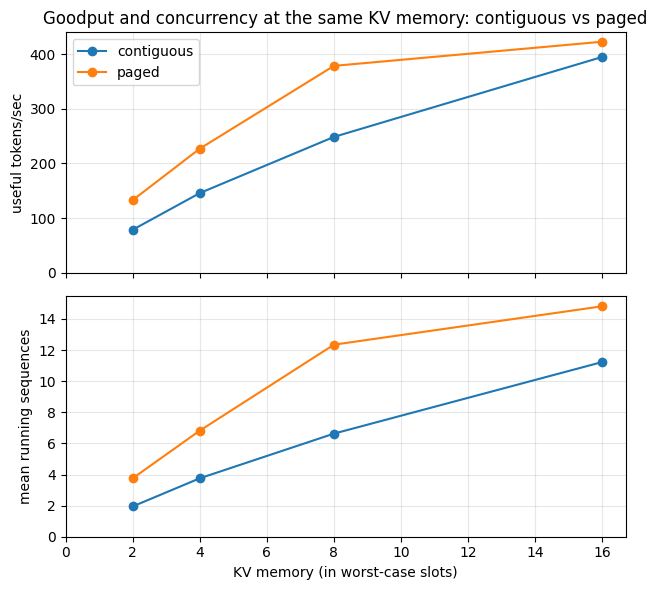

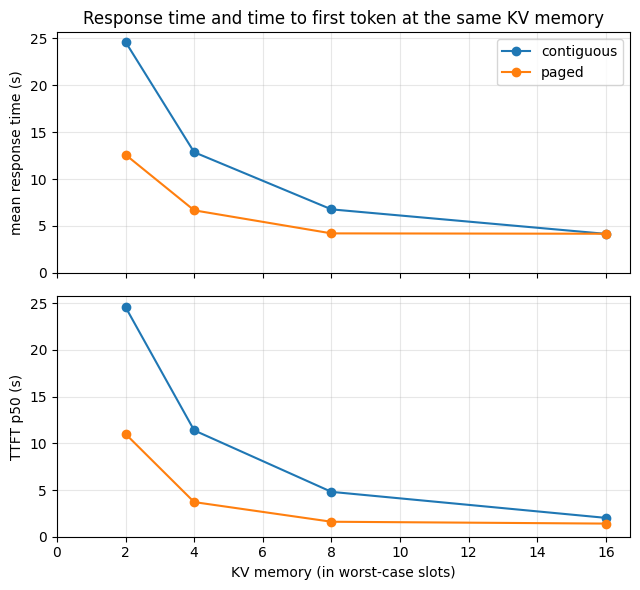

In [21]:
line_groups_stacked(mem_df, "budget_slots", ["goodput_tok_s", "mean_running"], "policy",
                    "Goodput and concurrency at the same KV memory: contiguous vs paged",
                    ["useful tokens/sec", "mean running sequences"],
                    xlabel="KV memory (in worst-case slots)", save="stage5_goodput_vs_memory")
line_groups_stacked(mem_df, "budget_slots", ["lat_mean_s", "ttft_p50_s"], "policy",
                    "Response time and time to first token at the same KV memory",
                    ["mean response time (s)", "TTFT p50 (s)"],
                    xlabel="KV memory (in worst-case slots)", save="stage5_latency_vs_memory")

**How to read it.**

- **Concurrency.** The contiguous cache runs about as many sequences as it has slots. The paged cache runs about twice as many at the same memory: it matches a contiguous cache with twice the bytes. The gap narrows only at the largest budget, where memory stops binding and the paged cache is held back by `MAX_SEQS` and by the requests that are left, not by memory.
- **Goodput.** It rises with the number of sequences per decode step (Stage 3's lesson: a step costs about the same for few or many rows), so paging wins by more than a third while memory is the limit. At the largest budget the win is small, and the paged cache pays for its gather (section 6).
- **Waiting.** In a closed batch every request arrives at once, so the time to first token of a request is the time it waits for memory (or a slot). It falls by even more than the mean response time, because far more requests are admitted at the start.
- The `mem_blocked_frac` column is the share of decode steps in which the request at the head of the queue was held back by memory. It is high at tight budgets and falls to zero when memory stops binding.
- Each point is a single run, so expect some noise.

---
## 5. B. Where the memory goes

**Goal:** account for every token of the pool, before and after.

**Concept.** At each decode step the pool splits into four parts. **Tokens stored** are real keys and values. **Reserved but empty** is memory given to a request for tokens it has not generated yet (and, for a contiguous slot, for tokens it will never need). **Block rounding** is the unused tail of each sequence's last block, at most one block per sequence. **Not handed out** is free memory in the pool, which the paged cache can give to the next request and the contiguous cache cannot. The cell averages these over the decode steps of the section 4 runs, so it takes no extra time.

> **Predict:** what share of the pool holds tokens in each cache? How large is the rounding at a block of 16 tokens?

In [22]:
def breakdown(r):
    # parts of the pool, as a share of it (they add up to 100)
    pool, stored = r.pool_tokens, r.kv_stored_mean
    if r.policy == "contiguous":
        parts = dict(stored=stored, reserved_empty=pool - stored, rounding=0.0, not_handed_out=0.0)
    else:
        parts = dict(stored=stored, reserved_empty=r.kv_need_mean - stored, rounding=r.kv_alloc_mean - r.kv_need_mean,
                     not_handed_out=pool - r.kv_alloc_mean)
    return {k: 100 * v / pool for k, v in parts.items()}

kv_df = pd.DataFrame([{"budget_slots": r.budget_slots, "policy": r.policy, "pool_mib": r.pool_mib,
                       "kv_fill_pct": 100 * r.kv_fill, **breakdown(r)} for r in mem_df.itertuples()])
kv_df.round(1)

,budget_slots,policy,pool_mib,kv_fill_pct,stored,reserved_empty,rounding,not_handed_out
0,2,contiguous,17.2,32.9,32.9,67.1,0.0,0.0
1,2,paged,17.2,75.2,63.8,19.2,1.8,15.2
2,4,contiguous,34.3,31.7,31.7,68.3,0.0,0.0
3,4,paged,34.3,75.2,57.6,17.3,1.6,23.5
4,8,contiguous,68.6,28.0,28.0,72.0,0.0,0.0
5,8,paged,68.6,75.2,52.1,15.7,1.5,30.7
6,16,contiguous,137.2,23.7,23.7,76.3,0.0,0.0
7,16,paged,137.2,75.2,31.3,9.4,0.9,58.4


In [23]:
kv_df_contig = kv_df[kv_df["policy"] == "contiguous"]
kv_df_paged = kv_df[kv_df["policy"] == "paged"]

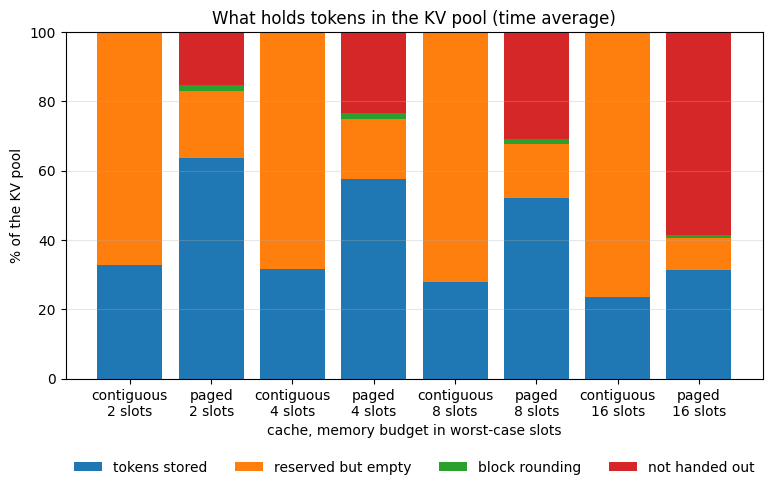

In [24]:
labels = [f"{r.policy}\n{r.budget_slots} slots" for r in kv_df.itertuples()]
stacked_bar(labels,
            {"tokens stored": list(kv_df["stored"]), "reserved but empty": list(kv_df["reserved_empty"]),
             "block rounding": list(kv_df["rounding"]), "not handed out": list(kv_df["not_handed_out"])},
            "What holds tokens in the KV pool (time average)", "% of the KV pool",
            xlabel="cache, memory budget in worst-case slots", ylim=(0, 100), figsize=(9, 4.5),
            save="stage5_kv_breakdown")

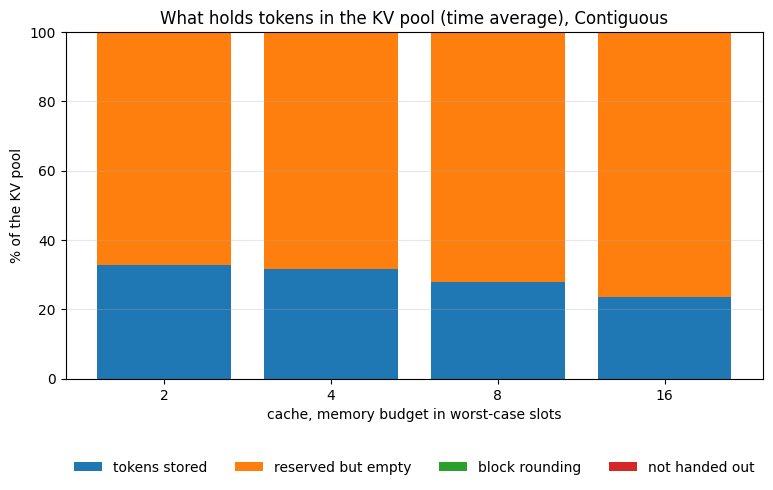

In [25]:
labels_contig = [f"{r.budget_slots}" for r in kv_df_contig.itertuples()]
stacked_bar(labels_contig,
            {"tokens stored": list(kv_df_contig["stored"]), 
             "reserved but empty": list(kv_df_contig["reserved_empty"]),
             "block rounding": list(kv_df_contig["rounding"]), 
             "not handed out": list(kv_df_contig["not_handed_out"])},
             "What holds tokens in the KV pool (time average), Contiguous", "% of the KV pool",
             xlabel="cache, memory budget in worst-case slots", ylim=(0, 100), figsize=(9, 4.5),
             save="stage5_kv_contig_breakdown")

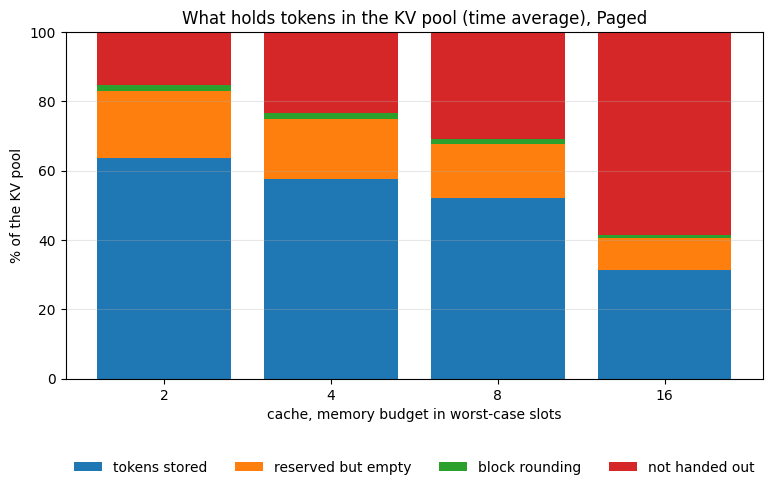

In [27]:
labels_paged = [f"{r.budget_slots}" for r in kv_df_paged.itertuples()]
stacked_bar(labels_paged,
            {"tokens stored": list(kv_df_paged["stored"]), 
             "reserved but empty": list(kv_df_paged["reserved_empty"]),
             "block rounding": list(kv_df_paged["rounding"]), 
             "not handed out": list(kv_df_paged["not_handed_out"])},
             "What holds tokens in the KV pool (time average), Paged", "% of the KV pool",
             xlabel="cache, memory budget in worst-case slots", ylim=(0, 100), figsize=(9, 4.5),
             save="stage5_kv_paged_breakdown")

**How to read it.** 

>_The two extra plots below split the same data by cache, so the bars of each are easier to compare across budgets._

- **Contiguous.** Most of the pool is reserved but empty, for the two reasons from Stage 4: every slot is sized for the *longest* request, and a running sequence is on average only part-way through its generation. The share that holds tokens falls as slots are added.
- **Paged.** A much larger share of the pool holds tokens at every budget, because a request is given its true size. What remains is memory reserved for tokens still to come (we reserve the whole request when it is admitted), a small block-rounding term, and memory that is not handed out. At a large budget most of that is slack the workload cannot use, which is free for the next request. But even at the tightest budget some memory is not handed out while requests wait: the first request in line needs more blocks than are free, and strict first come, first served keeps the smaller requests behind it waiting (exercise 5).
- **Rounding is small and bounded.** It is at most one block per running sequence, so it does not grow with the length of the requests. Section 6 shows how it changes with the block size.
- **Reserved but empty is the largest paged waste at tight budgets**, because of the up-front reservation. Reserving lazily, one block at a time, would shrink it, at the price of preemption when the pool runs out (exercise 1).

---
## 6. C. The price: the gather, and how big a block should be

**Goal:** measure what reading the cache through a block table costs, and how the block size trades waste against speed.

**Concept.** Two things depend on the block size. **Waste:** the last block of a sequence is partly empty, on average half a block, so larger blocks waste more. **Speed:** the decode step gathers every running sequence's blocks into a dense tensor before attention, so it pays a copy of the keys and values in use plus a few extra kernel launches per layer. Larger blocks mean fewer, bigger copies and a shorter block table, but the gather also pads each sequence up to a whole number of blocks, so very large blocks copy columns that nobody reads. The reference is the contiguous cache with the same number of concurrent sequences, which reads its keys and values in place.

**Setup.** Memory is plentiful here (no request ever waits for it), `C_SEQS` sequences run at once, and only the block size changes. The same requests as section 4.

> **Predict:** how does the rounding waste change as the block size grows by 16 times? Is the paged decode step slower than the contiguous one, and by how much?

In [28]:
C_SEQS = 16
BLOCK_SIZES = [16, 64] if QUICK else [8, 16, 32, 64, 128, 256]
bs_rows = []
ref = summarize_online(run_continuous(model, mem_reqs, C_SEQS, PAD_ID))
bs_rows.append({"policy": "contiguous (reference)", "block_size": None, **ref})
for bs in BLOCK_SIZES:
    blocks = C_SEQS * -(-MAX_LEN // bs)                      # enough for every sequence to be a worst-case one
    bs_rows.append({"policy": "paged", "block_size": bs, **summarize_online(run_paged(model, mem_reqs, blocks, bs, C_SEQS, PAD_ID))})
bs_df = pd.DataFrame(bs_rows)
bs_df["rounding_pct"] = 100 * (bs_df.kv_alloc_mean - bs_df.kv_need_mean) / bs_df.kv_alloc_mean
bs_df["step_vs_contiguous_x"] = bs_df.itl_p50_ms / ref["itl_p50_ms"]
bs_df[["policy", "block_size", "goodput_tok_s", "itl_p50_ms", "step_vs_contiguous_x", "rounding_pct", "mean_running"]].round(2)

,policy,block_size,goodput_tok_s,itl_p50_ms,step_vs_contiguous_x,rounding_pct,mean_running
0,contiguous (reference),NaN,391.71,24.96,1.00,NaN,11.23
1,paged,8.0,355.00,27.44,1.10,1.18,11.23
2,paged,16.0,356.15,27.34,1.10,2.13,11.23
3,paged,32.0,356.99,27.27,1.09,4.52,11.23
4,paged,64.0,357.42,27.23,1.09,8.63,11.23
5,paged,128.0,356.15,27.30,1.09,18.58,11.23
6,paged,256.0,356.85,27.25,1.09,33.70,11.23


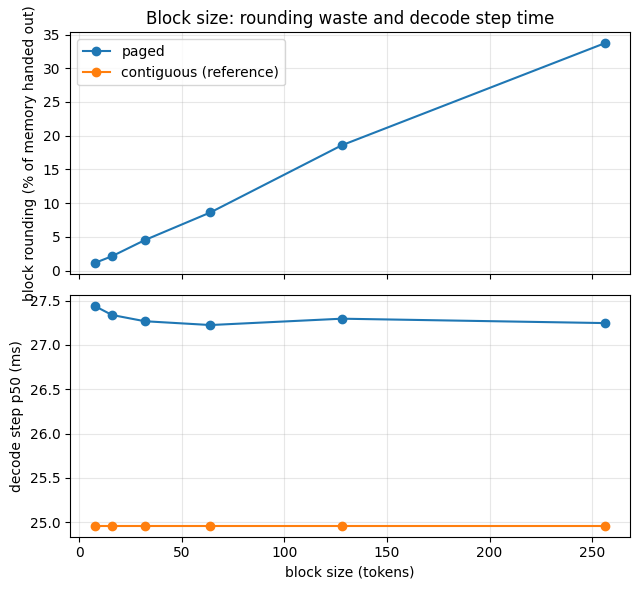

In [29]:
# the contiguous reference is drawn as a flat line across the block sizes
ref_rows = pd.DataFrame([{"policy": "contiguous (reference)", "block_size": bs, "itl_p50_ms": ref["itl_p50_ms"],
                          "rounding_pct": np.nan} for bs in BLOCK_SIZES])
plot_df = pd.concat([bs_df[bs_df.policy == "paged"][["policy", "block_size", "itl_p50_ms", "rounding_pct"]], ref_rows])
line_groups_stacked(plot_df, "block_size", ["rounding_pct", "itl_p50_ms"], "policy",
                    "Block size: rounding waste and decode step time",
                    ["block rounding (% of memory handed out)", "decode step p50 (ms)"],
                    xlabel="block size (tokens)", zero=False, save="stage5_block_size")

**How to read it.**

- **Rounding waste grows with the block size**, about in proportion, since it is about half a block per sequence. It is a small share of the memory at small blocks and a large share at the largest, where a short request is given far more than it needs.
- **The gather costs a little.** The paged decode step is somewhat slower than the contiguous step at the same concurrency, because it copies the keys and values it uses and launches a few more kernels per layer. In this launch-bound regime the cost is modest, and a kernel that reads the blocks in place would not pay it (exercise 2).
- **The step time does not depend on the block size** over the range tested: the gather copies the same bytes and launches the same kernels whatever the block size. So in this experiment smaller blocks are strictly better. What makes very small blocks costly in a real kernel (a longer block table, less efficient memory access) is not visible here, which is why real systems pick a block of a few tens of tokens.
- Each point is a single run, so expect some noise.

---
## 7. D. Open-loop load at fixed memory

**Goal:** see how each cache behaves when requests arrive over time with a tight KV budget, which is how a memory-bound server is used.

**Setup.** `N_MEM` mixed requests arrive as a **Poisson process** at several rates (requests per second, the *offered load*). Both caches have the same memory, `LOAD_BUDGET` worst-case slots, and see the **same** arrival trace at each rate. The paged cache admits a request when it has enough free blocks and fewer than `MAX_SEQS` sequences run.

**Concept.** At a low rate there are few requests to run at once, so both caches behave alike. As the rate rises, the contiguous cache has only `LOAD_BUDGET` slots, so requests queue for a slot long before the GPU is busy, and its completed rate flattens. The paged cache admits as long as there are free blocks, so it keeps more sequences running, its queue stays shorter, and its completed rate flattens later.

> **Predict:** at what offered load does each cache stop keeping up? Does the response time at light load differ?

In [30]:
LOAD_BUDGET = 4
RATES = [1, 3] if QUICK else [1, 2, 3, 4, 6]            # offered load, requests per second
load_rows = []
for rate in RATES:
    load_rows += sweep_memory(model, mem_reqs, [LOAD_BUDGET], block_size=BLOCK, max_seqs=MAX_SEQS, pad_id=PAD_ID,
                              rate=rate, arrival_seed=1)
load_df = pd.DataFrame(load_rows)
load_df[["rate", "policy", "req_s", "goodput_tok_s", "mean_running", "queue_mean_s", "lat_p50_s", "lat_p99_s",
         "ttft_p50_s", "ttft_p99_s", "mem_blocked_frac"]].round(2)

memory =  4 worst-case slots  contiguous   64.0 s  goodput     67 tok/s  running  2.1  fill 0.18
memory =  4 worst-case slots  paged        64.6 s  goodput     66 tok/s  running  2.2  fill 0.75
memory =  4 worst-case slots  contiguous   36.1 s  goodput    119 tok/s  running  3.2  fill 0.27
memory =  4 worst-case slots  paged        35.6 s  goodput    120 tok/s  running  3.5  fill 0.75
memory =  4 worst-case slots  contiguous   30.2 s  goodput    142 tok/s  running  3.6  fill 0.31
memory =  4 worst-case slots  paged        27.0 s  goodput    159 tok/s  running  4.5  fill 0.75
memory =  4 worst-case slots  contiguous   29.7 s  goodput    144 tok/s  running  3.7  fill 0.31
memory =  4 worst-case slots  paged        23.2 s  goodput    185 tok/s  running  5.3  fill 0.75
memory =  4 worst-case slots  contiguous   29.5 s  goodput    145 tok/s  running  3.7  fill 0.31
memory =  4 worst-case slots  paged        19.8 s  goodput    216 tok/s  running  6.3  fill 0.75


,rate,policy,req_s,goodput_tok_s,mean_running,queue_mean_s,lat_p50_s,lat_p99_s,ttft_p50_s,ttft_p99_s,mem_blocked_frac
0,1,contiguous,1.00,67.00,2.12,0.05,0.98,6.53,0.04,0.61,NaN
1,1,paged,0.99,66.40,2.25,0.01,1.06,7.26,0.04,0.08,0.00
2,2,contiguous,1.77,118.86,3.16,0.63,1.61,7.35,0.13,2.50,NaN
3,2,paged,1.80,120.42,3.48,0.04,1.08,7.32,0.04,0.70,0.04
4,3,contiguous,2.12,141.92,3.62,2.33,4.13,10.72,2.28,5.62,NaN
5,3,paged,2.37,159.00,4.53,0.15,1.21,7.58,0.04,1.70,0.14
6,4,contiguous,2.16,144.40,3.68,4.35,6.61,15.07,5.11,10.07,NaN
7,4,paged,2.76,185.05,5.33,0.25,1.27,8.55,0.05,2.63,0.23
8,6,contiguous,2.17,145.40,3.71,6.52,8.58,19.74,6.94,14.87,NaN
9,6,paged,3.22,215.97,6.32,0.87,2.04,10.11,0.50,4.29,0.49


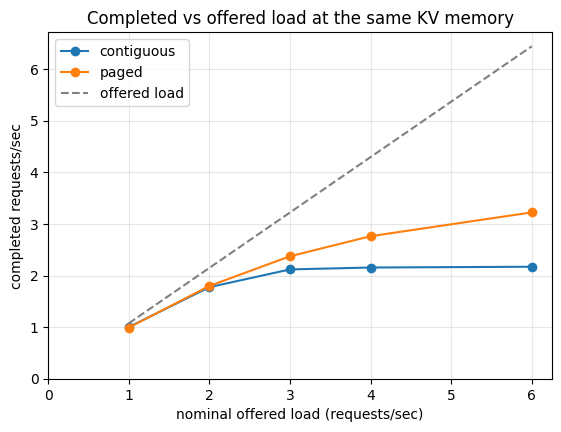

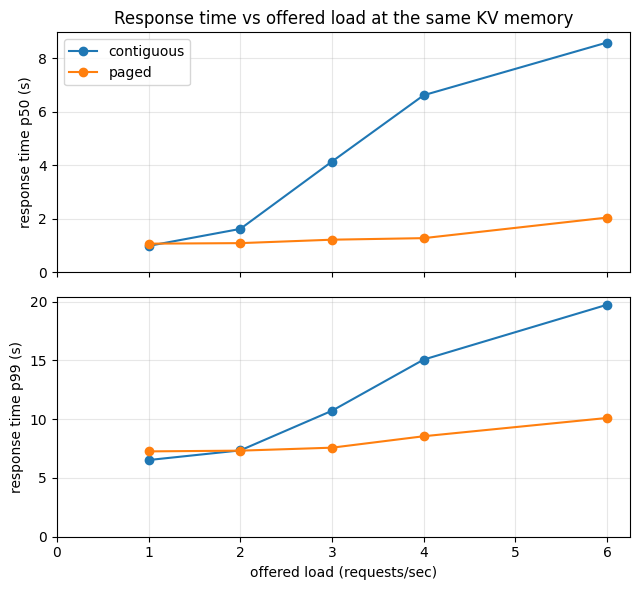

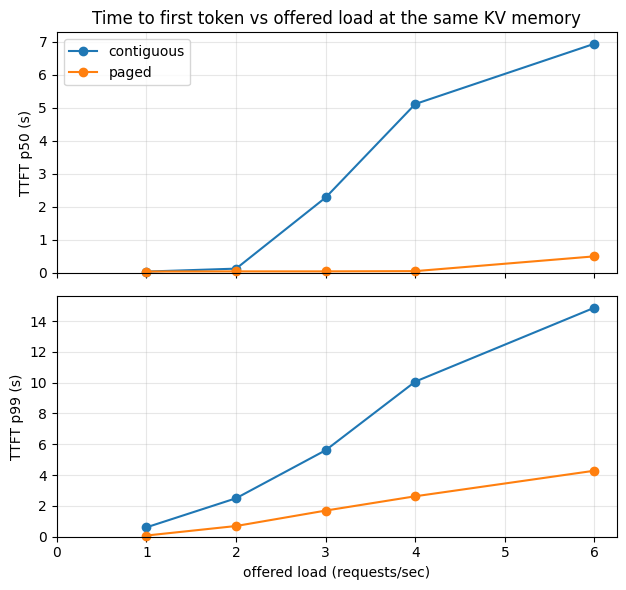

In [31]:
# the dashed line is the arrival rate the random trace actually realized, which scatters around the nominal rate
offered = (load_df[load_df.policy == "contiguous"][["rate", "offered_req_s"]]
           .rename(columns={"offered_req_s": "req_s"}).assign(policy="offered load"))
line_groups(pd.concat([load_df[["rate", "req_s", "policy"]], offered]), "rate", "req_s", "policy",
            "Completed vs offered load at the same KV memory", "completed requests/sec",
            xlabel="nominal offered load (requests/sec)", save="stage5_throughput_vs_load")
line_groups_stacked(load_df, "rate", ["lat_p50_s", "lat_p99_s"], "policy", "Response time vs offered load at the same KV memory",
                    ["response time p50 (s)", "response time p99 (s)"], xlabel="offered load (requests/sec)",
                    save="stage5_latency_vs_load")
line_groups_stacked(load_df, "rate", ["ttft_p50_s", "ttft_p99_s"], "policy", "Time to first token vs offered load at the same KV memory",
                    ["TTFT p50 (s)", "TTFT p99 (s)"], xlabel="offered load (requests/sec)", save="stage5_ttft_vs_load")

**How to read it.**

- **Light load.** With few requests in flight the memory is not the limit, so the two caches look alike. The difference starts when the arrival rate is high enough that more requests are waiting than the contiguous cache has slots.
- **The contiguous cache queues first.** Its slots are full while memory is mostly empty, so new requests wait for a slot, its time to first token climbs, and its completed rate flattens at a low level well below the offered load: that is its capacity at this memory.
- **The paged cache keeps admitting.** It runs more sequences in each decode step, so its response and first-token times stay low for longer, and its completed rate is still rising at the top of the sweep, so its capacity at the same memory is at least that high. It too saturates, when memory or `MAX_SEQS` runs out, and `mem_blocked_frac` shows when memory is what holds requests back.
- **Read saturation from the queue.** As in Stage 4, the completed rate of a finite trace understates capacity, because the trace ends only when the last long request has drained. Use the time to first token and the queueing time.
- The p99 over a few dozen requests is simply the slowest request, so read the p50 as the typical experience. The arrival trace is one random sample per rate, so expect some noise, especially in the tail.

---
## 8. Save results

`results/stage5.json` holds everything needed to re-plot without re-running:

- `env` and `config`: GPU, library versions, model revision, and every experiment parameter,
- `memory`: section 4 (contiguous vs paged at each memory budget),
- `kv_breakdown`: section 5,
- `block_size`: section 6 (one row per block size, plus the contiguous reference),
- `load`: section 7 (both caches at each offered load).

Final published numbers should come from one consistent environment.

In [32]:
def records(df):
    # JSON has no NaN: missing values become null
    return df.round(4).astype(object).where(pd.notnull(df), None).to_dict(orient="records")

out = {
    "env": {**ENV, "max_pos": MAX_POS},
    "config": {
        "seed": SEED, "quick": QUICK, "workload": "mixed", "workloads": WORKLOADS,
        "memory": {"n_requests": N_MEM, "budgets": MEM_BUDGETS, "block_size": BLOCK, "max_seqs": MAX_SEQS, "max_len": MAX_LEN},
        "block_size": {"concurrency": C_SEQS, "block_sizes": BLOCK_SIZES},
        "load": {"n_requests": N_MEM, "budget_slots": LOAD_BUDGET, "rates": RATES, "arrival_seed": 1,
                 "block_size": BLOCK, "max_seqs": MAX_SEQS},
        "short_max_new": 48,
        "bytes_per_token": bpt,
    },
    "memory": records(mem_df),
    "kv_breakdown": records(kv_df),
    "block_size": records(bs_df),
    "load": records(load_df),
}
save_results("results/stage5.json", out)

saved results/stage5.json


### Figure inventory

Every figure was written to `results/` by the cell that produced it. This cell lists them and fails if one is missing.

In [33]:
FIGURES = {
    "stage5_goodput_vs_memory.png": "Goodput and mean running sequences vs KV memory, contiguous vs paged (section 4)",
    "stage5_latency_vs_memory.png": "Mean response time and TTFT p50 vs KV memory, contiguous vs paged (section 4)",
    "stage5_kv_breakdown.png": "What holds tokens in the KV pool, by cache and memory budget (section 5)",
    "stage5_kv_contig_breakdown.png": "What holds tokens in the KV pool, by cache and memory budget - contiguous (section 5)",
    "stage5_kv_paged_breakdown.png": "What holds tokens in the KV pool, by cache and memory budget - paged (section 5)",
    "stage5_block_size.png": "Rounding waste and decode step time vs block size, with the contiguous reference (section 6)",
    "stage5_throughput_vs_load.png": "Completed vs offered load at the same KV memory, contiguous vs paged (section 7)",
    "stage5_latency_vs_load.png": "Response time p50 and p99 vs offered load at the same KV memory (section 7)",
    "stage5_ttft_vs_load.png": "Time to first token p50 and p99 vs offered load at the same KV memory (section 7)",
}
missing = [f for f in FIGURES if not os.path.exists(f"results/{f}")]
assert not missing, f"missing figures: {missing}"
pd.DataFrame({"file": list(FIGURES), "what it shows": list(FIGURES.values())})

,file,what it shows
0,stage5_goodput_vs_memory.png,Goodput and mean running sequences vs KV memor...
1,stage5_latency_vs_memory.png,"Mean response time and TTFT p50 vs KV memory, ..."
2,stage5_kv_breakdown.png,"What holds tokens in the KV pool, by cache and..."
3,stage5_kv_contig_breakdown.png,"What holds tokens in the KV pool, by cache and..."
4,stage5_kv_paged_breakdown.png,"What holds tokens in the KV pool, by cache and..."
5,stage5_block_size.png,Rounding waste and decode step time vs block s...
6,stage5_throughput_vs_load.png,Completed vs offered load at the same KV memor...
7,stage5_latency_vs_load.png,Response time p50 and p99 vs offered load at t...
8,stage5_ttft_vs_load.png,Time to first token p50 and p99 vs offered loa...


---
## 9. Publish results (and code, if this is the newest notebook) to GitHub (optional)

Set `PUSH = True` to push this run to your repo. The cell below is identical in every notebook of the series except `PUSH` and `COMMIT_MSG`. It calls `publish()` from `bench/publish.py`, which clones the repo, pulls, copies `results/` in, and copies `minivllm/` and `bench/` in only if this notebook's stage is at least the stage recorded in the repo (`minivllm/STAGE`). It then commits and pushes, printing git's output and raising an error if any git step fails. This is the newest notebook, so it publishes code as well as results. An older notebook rerun later pushes results only and cannot overwrite this code.

It needs a Kaggle secret named `minivllm-github-token` holding a GitHub token with write access. The repo name and git identity are constants at the top of `bench/publish.py`. The token is used only for the clone, pull and push commands and is not stored in the repo's git config.

In [34]:
PUSH = True                              # True: publish to GitHub at the end of the run
COMMIT_MSG = "Stage 5: paged KV cache"   # the only other line that differs between notebooks
FORCE_CODE = False                       # leave False: code is published automatically from the newest stage

if PUSH:
    from kaggle_secrets import UserSecretsClient
    from bench.publish import publish, SECRET_NAME
    publish(token=UserSecretsClient().get_secret(SECRET_NAME), message=COMMIT_MSG, force_code=FORCE_CODE)

Cloning into 'mini-vllm'...
remote: Enumerating objects: 767, done.        
remote: Counting objects: 100% (154/154), done.        
remote: Compressing objects: 100% (124/124), done.        
remote: Total 767 (delta 72), reused 92 (delta 28), pack-reused 613 (from 1)        
Receiving objects: 100% (767/767), 17.32 MiB | 23.90 MiB/s, done.
Resolving deltas: 100% (370/370), done.
Already up to date.
From https://github.com/chizkidd/minivllm
 * branch            HEAD       -> FETCH_HEAD
notebook stage 5, repo code stage 5: publishing code and results
[main 5d4e015] Stage 5: paged KV cache
 10 files changed, 591 insertions(+), 592 deletions(-)
 create mode 100644 results/stage5_kv_contig_breakdown.png
 create mode 100644 results/stage5_kv_paged_breakdown.png
Enumerating objects: 23, done.
Counting objects: 100% (23/23), done.
Delta compression using up to 4 threads
Compressing objects: 100% (14/14), done.
Writing objects: 100% (14/14), 476.10 KiB | 17.63 MiB/s, done.
Total 14 (delta 5), r

---
## 10. Summary

In [35]:
from IPython.display import Markdown, display

def show_table(rows, headers=("Metric", "Result", "Note")):
    esc = lambda c: str(c).replace("|", "\\|")   # a literal | would break the table
    out_ = ["| " + " | ".join(headers) + " |", "|" + "|".join(["---"] * len(headers)) + "|"]
    for r in rows:
        out_.append("| " + " | ".join([f"**{esc(r[0])}**"] + [esc(c) for c in r[1:]]) + " |")
    display(Markdown("\n".join(out_)))

tight = min(MEM_BUDGETS)
mc, mp = (mem_df[(mem_df.budget_slots == tight) & (mem_df.policy == p)].iloc[0] for p in ("contiguous", "paged"))
kc, kp = (kv_df[(kv_df.budget_slots == tight) & (kv_df.policy == p)].iloc[0] for p in ("contiguous", "paged"))
b_ref = bs_df[bs_df.policy == "contiguous (reference)"].iloc[0]
b_small, b_big = bs_df[bs_df.policy == "paged"].iloc[0], bs_df[bs_df.policy == "paged"].iloc[-1]
b_mid = bs_df[(bs_df.policy == "paged") & (bs_df.block_size == BLOCK)].iloc[0]
hi = load_df[load_df.rate == load_df.rate.max()]
hc, hp = hi[hi.policy == "contiguous"].iloc[0], hi[hi.policy == "paged"].iloc[0]

show_table([
    (f"Running sequences at {tight} worst-case slots of memory",
     f"contiguous {mc.mean_running:.1f} -> paged {mp.mean_running:.1f}",
     f"{mp.mean_running / mc.mean_running:.1f}x, same bytes, same requests"),
    (f"Goodput at {tight} worst-case slots of memory",
     f"contiguous {mc.goodput_tok_s:.0f} -> paged {mp.goodput_tok_s:.0f} tok/s",
     f"{mp.goodput_tok_s / mc.goodput_tok_s:.1f}x"),
    (f"Mean response time at {tight} worst-case slots of memory",
     f"contiguous {mc.lat_mean_s:.1f} s -> paged {mp.lat_mean_s:.1f} s",
     f"TTFT p50 {mc.ttft_p50_s:.1f} s -> {mp.ttft_p50_s:.1f} s"),
    ("Share of the pool that holds tokens",
     f"contiguous {kc.stored:.0f}% -> paged {kp.stored:.0f}%",
     f"block rounding {kp.rounding:.1f}% of the pool at {BLOCK}-token blocks"),
    (f"Block size {int(b_small.block_size)} vs {int(b_big.block_size)}",
     f"rounding {b_small.rounding_pct:.1f}% vs {b_big.rounding_pct:.1f}% of the memory handed out",
     f"decode step p50 {b_small.itl_p50_ms:.0f} ms vs {b_big.itl_p50_ms:.0f} ms"),
    (f"The gather at {BLOCK}-token blocks",
     f"decode step p50 contiguous {b_ref.itl_p50_ms:.1f} ms -> paged {b_mid.itl_p50_ms:.1f} ms",
     f"{b_mid.itl_p50_ms / b_ref.itl_p50_ms:.2f}x at {C_SEQS} sequences"),
    (f"Latency p50 at {hi.rate.iloc[0]} req/s",
     f"contiguous {hc.lat_p50_s:.1f} s, paged {hp.lat_p50_s:.1f} s",
     f"completed {hc.req_s:.1f} vs {hp.req_s:.1f} req/s, offered {hc.offered_req_s:.1f}"),
    (f"TTFT p50 at {hi.rate.iloc[0]} req/s",
     f"contiguous {hc.ttft_p50_s:.1f} s, paged {hp.ttft_p50_s:.1f} s", "queueing for a slot vs for blocks"),
])

| Metric | Result | Note |
|---|---|---|
| **Running sequences at 2 worst-case slots of memory** | contiguous 1.9 -> paged 3.8 | 1.9x, same bytes, same requests |
| **Goodput at 2 worst-case slots of memory** | contiguous 79 -> paged 133 tok/s | 1.7x |
| **Mean response time at 2 worst-case slots of memory** | contiguous 24.6 s -> paged 12.6 s | TTFT p50 24.6 s -> 11.0 s |
| **Share of the pool that holds tokens** | contiguous 33% -> paged 64% | block rounding 1.8% of the pool at 16-token blocks |
| **Block size 8 vs 256** | rounding 1.2% vs 33.7% of the memory handed out | decode step p50 27 ms vs 27 ms |
| **The gather at 16-token blocks** | decode step p50 contiguous 25.0 ms -> paged 27.3 ms | 1.10x at 16 sequences |
| **Latency p50 at 6 req/s** | contiguous 8.6 s, paged 2.0 s | completed 2.2 vs 3.2 req/s, offered 6.4 |
| **TTFT p50 at 6 req/s** | contiguous 6.9 s, paged 0.5 s | queueing for a slot vs for blocks |

### What we learned

#### Questions

- **Does paging fit more sequences in the same memory?** (Section 4: running sequences, goodput and response time at a fixed KV budget.)
- **Where does the memory go before and after?** (Section 5: tokens stored, reserved, rounded and unused.)
- **What does it cost?** (Section 6: the gather, and the block size trade-off.)
- **Does it matter under load?** (Section 7: capacity at a fixed KV budget.)

#### Answers

- **Yes, paging fits more sequences in the same memory.** At a fixed KV budget the paged cache runs about twice as many sequences as the contiguous one, so goodput rises by more than a third and response times fall while memory is the limit, with time to first token falling the most. When memory is plentiful the gap closes.
- **The memory goes into tokens instead of reservation.** Only a minority of the contiguous pool holds tokens. In the paged pool most does, with a small rounding term, some memory reserved for tokens still to come, and some stranded when the request at the head of the queue does not fit.
- **It costs a slightly slower step and block-size waste.** Reading through the block table costs a gather, a modest slowdown that does not depend on the block size here, while the unused tail of each last block grows with it.
- **It matters under load.** With the same memory, the contiguous cache queues early and its completed rate flattens, while the paged cache keeps admitting, completes more requests, and keeps its time to first token low.

### Next: Stage 6, a stretch

The engine now uses its memory well and keeps the batch full. What is left is the cost of each step: every decode step still reads all the weights, and a paged-attention kernel could read the blocks in place instead of gathering them. Stage 6 picks one of two directions: **quantize the weights** (int8 or fp8), so each step reads fewer bytes, or **speculative decoding**, where a small draft model proposes several tokens and the big model checks them in one pass, so one weight read can yield several tokens.

### Exercises

1. **Allocate lazily.** Reserve only the blocks a sequence has filled and add one block when it needs one. When the pool runs dry, preempt the newest sequence: free its blocks and put it back at the head of the queue to be prefilled again. How much more memory does this save, and what happens to the tail latency of preempted requests?
2. **Measure the gather.** Time a decode step that gathers through the block table against one that reads a pre-gathered dense tensor of the same size. How much of the paged decode step is the copy? Then write the attention so it reads blocks in place (a Triton kernel, or a loop over blocks with an online softmax) and compare.
3. **Share a prefix.** Give two requests with the same prompt the same prompt blocks, with a reference count, and copy a block only when one sequence writes into it (copy on write). How much memory does a batch of requests with a long shared system prompt save?
4. **Pick the block size.** Sweep the block size at a tight memory budget with short requests, and again with long ones. Where does the best block size move?
5. **Admit smarter.** Instead of strict first come, first served, admit the first waiting request that fits. What does it do to throughput, and to the tail latency of the large request that keeps being passed over?

### References

- Kwon et al., *Efficient Memory Management for LLM Serving with PagedAttention* (vLLM): https://arxiv.org/abs/2309.06180
- Yu et al., *Orca: A Distributed Serving System for Transformer-Based Generative Models* (OSDI 2022), iteration-level (continuous) scheduling: https://www.usenix.org/conference/osdi22/presentation/yu
- Leviathan et al., *Fast Inference from Transformers via Speculative Decoding*: https://arxiv.org/abs/2211.17192

---

# Appendix

Refer to the simple examples below to understand how the block allocator, the paged cache and the paged scheduler work.

## A.1. The block allocator (`BlockAllocator`)

In [36]:
from minivllm.block_allocator import BlockAllocator

a = BlockAllocator(8)
x = a.allocate(3)                       # request A needs 3 blocks
y = a.allocate(2)                       # request B needs 2 blocks
print("A holds", x, "| B holds", y, "| free:", a.num_free)

a.free(x)                               # A finishes: its blocks go to the back of the free queue
z = a.allocate(4)                       # request C needs 4 blocks: the never-used ones come first, then A's
print("after A leaves, C holds", z, "(its blocks are scattered: no run of neighbours)")

try:
    a.allocate(3)
except MemoryError as e:
    print("a request that does not fit is refused:", e)

A holds [0, 1, 2] | B holds [3, 4] | free: 3
after A leaves, C holds [5, 6, 7, 0] (its blocks are scattered: no run of neighbours)
a request that does not fit is refused: need 3 blocks, only 2 free


## A.2. A paged cache (`PagedCache`): block tables and addresses

In [37]:
from minivllm.kv_cache import PagedCache

c = PagedCache(n_layers=1, num_blocks=6, block_size=4, n_kv_heads=1, head_dim=2, device="cpu", dtype=torch.float32)
k = lambda T: torch.arange(T * 2, dtype=torch.float32).view(1, 1, T, 2)

c.add("A", 10)                          # up to 10 tokens -> 3 blocks of 4
c.add("B", 5)                           # up to 5 tokens  -> 2 blocks
view = c.prefill_view("A"); view.update(0, k(6), k(6)); view.advance(6)     # a 6-token prompt for A
view = c.prefill_view("B"); view.update(0, k(3), k(3)); view.advance(3)     # a 3-token prompt for B
print("block tables:", c.tables, "| tokens stored:", c.lens)
print("A's token 5 lives in block", c.tables["A"][5 // 4], "at offset", 5 % 4)

dv = c.decode_view(["A", "B"])          # one new token for each; each writes at its own position
print("the next token of A goes to block", dv.wblk[0].item(), "offset", dv.woff[0].item(),
      "| of B to block", dv.wblk[1].item(), "offset", dv.woff[1].item())
print("block table the gather uses (rows = A, B):", dv.table.tolist(), "| columns that can matter:", dv.end)

c.free("A")
print("\nafter A finishes: free blocks =", c.allocator.num_free, "-> the next request can take them at once; their keys are masked, not erased")

block tables: {'A': [0, 1, 2], 'B': [3, 4]} | tokens stored: {'A': 6, 'B': 3}
A's token 5 lives in block 1 at offset 1
the next token of A goes to block 1 offset 2 | of B to block 3 offset 3
block table the gather uses (rows = A, B): [[0, 1], [3, 4]] | columns that can matter: 7

after A finishes: free blocks = 4 -> the next request can take them at once; their keys are masked, not erased


## A.3. Five toy requests, two caches, the same memory

The same five requests go through `run_continuous` (two contiguous slots) and `run_paged` (the same memory cut into blocks of 2 tokens, so the toy needs no more than a handful). Request 1 has a long answer, the others are short. Requests 2 and 3 arrive while the first two are still running, and request 4 arrives when everything is idle. The helper draws a timeline with one row per request, one character per 20 ms.

In [38]:
toy = [Request(0, tok("The capital of France is").input_ids, 4, arrival_s=0.00),
       Request(1, tok("Once upon a time there was").input_ids, 12, arrival_s=0.00),
       Request(2, tok("2 + 2 =").input_ids, 3, arrival_s=0.05),
       Request(3, tok("def add(a, b):").input_ids, 6, arrival_s=0.10),
       Request(4, tok("Hello").input_ids, 2, arrival_s=0.40)]

def gantt(results, dt=0.02, title=""):
    # one row per request, one character per `dt` seconds
    end = max(r.release_s for r in results)
    n = int(round(end / dt)) + 1
    print(f"{title}   (one character = {int(dt*1000)} ms, total {end:.2f} s)")
    for r in sorted(results, key=lambda r: r.id):
        row = ""
        for i in range(n):
            t = i * dt
            row += (" " if t < r.arrival_s else "." if t < r.admit_s else "P" if t < r.first_token_s else
                    "#" if t < r.finish_s else " ")
        print(f"  request {r.id} |{row}|")
    print("  . waiting   P prefill   # decoding\n")

toy_need = [len(r.prompt_ids) + r.max_new - 1 for r in toy]
toy_len = max(toy_need)
TOY_SLOTS, TOY_BLOCK = 2, 2
toy_blocks = TOY_SLOTS * toy_len // TOY_BLOCK
print("tokens each request stores:", toy_need, "| 2 worst-case slots =", TOY_SLOTS * toy_len, "tokens =", toy_blocks, "blocks of", TOY_BLOCK)
pd.DataFrame([{"id": r.id, "arrival": r.arrival_s, "prompt tokens": len(r.prompt_ids), "new tokens": r.max_new,
               "stores": n, "blocks": -(-n // TOY_BLOCK)} for r, n in zip(toy, toy_need)])

tokens each request stores: [8, 17, 7, 11, 2] | 2 worst-case slots = 34 tokens = 17 blocks of 2


,id,arrival,prompt tokens,new tokens,stores,blocks
0,0,0.00,5,4,8,4
1,1,0.00,6,12,17,9
2,2,0.05,5,3,7,4
3,3,0.10,6,6,11,6
4,4,0.40,1,2,2,1


In [39]:
toy_cont = run_continuous(model, toy, slots=TOY_SLOTS, pad_id=PAD_ID)
gantt(toy_cont.results, title="contiguous, 2 slots")
toy_paged = run_paged(model, toy, num_blocks=toy_blocks, block_size=TOY_BLOCK, max_seqs=8, pad_id=PAD_ID)
gantt(toy_paged.results, title="paged, same memory")
print("running sequences per decode step, contiguous:", [s["active"] for s in toy_cont.steps])
print("running sequences per decode step, paged:     ", [s["active"] for s in toy_paged.steps])
print("blocks handed out per decode step, paged:     ", [s["kv_alloc_tokens"] // TOY_BLOCK for s in toy_paged.steps])

contiguous, 2 slots   (one character = 20 ms, total 0.45 s)
  request 0 |PP#####                |
  request 1 |..P################    |
  request 2 |   ....P###            |
  request 3 |     ......P######     |
  request 4 |                    PP#|
  . waiting   P prefill   # decoding

paged, same memory   (one character = 20 ms, total 0.45 s)
  request 0 |PP######                |
  request 1 |..P#################    |
  request 2 |   .PP##                |
  request 3 |     ...P#######        |
  request 4 |                    PP# |
  . waiting   P prefill   # decoding

running sequences per decode step, contiguous: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1]
running sequences per decode step, paged:      [2, 3, 3, 2, 2, 2, 2, 2, 1, 1, 1, 1]
blocks handed out per decode step, paged:      [13, 17, 17, 15, 15, 15, 15, 15, 9, 9, 9, 1]


Compare the two timelines. With the same memory the paged cache holds more requests at once, because a short request needs only a few blocks, so the later requests start sooner and everything finishes earlier. A request waits (the `.` characters) only when the free blocks cannot hold it, and it starts the moment a finished request returns enough of them.